In [ ]:
# Section A
#Question 1: Display first 10 and last 10 records

"""
Indian Flight Fare Analysis and Prediction
Author: Anchal
Description: End-to-end EDA notebook
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Global plot configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['figure.dpi'] = 100


# Loading the main dataset
df = pd.read_csv("Clean_Dataset.csv")

# Display first 10 records
display(df.head(10))

# Display last 10 records
display(df.tail(10))

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
5,5,Vistara,UK-945,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.33,1,5955
6,6,Vistara,UK-927,Delhi,Morning,zero,Morning,Mumbai,Economy,2.08,1,6060
7,7,Vistara,UK-951,Delhi,Afternoon,zero,Evening,Mumbai,Economy,2.17,1,6060
8,8,GO_FIRST,G8-334,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.17,1,5954
9,9,GO_FIRST,G8-336,Delhi,Afternoon,zero,Evening,Mumbai,Economy,2.25,1,5954


,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
300143,300143,Air_India,AI-440,Chennai,Early_Morning,one,Night,Hyderabad,Business,17.42,49,51345
300144,300144,Air_India,AI-539,Chennai,Evening,one,Morning,Hyderabad,Business,18.92,49,51345
300145,300145,Air_India,AI-430,Chennai,Morning,one,Morning,Hyderabad,Business,23.08,49,51345
300146,300146,Air_India,AI-440,Chennai,Early_Morning,one,Morning,Hyderabad,Business,26.83,49,51345
300147,300147,Air_India,AI-569,Chennai,Early_Morning,one,Night,Hyderabad,Business,17.25,49,68739
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585
300152,300152,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,81585


In [ ]:
#Question 2: Find rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Total records:", df.shape)

# One row represents one flight-booking observation, containing details such as airline, route, journey characteristics, class and ticket price.


Number of rows: 300153
Number of columns: 12
Total records: (300153, 12)


In [ ]:
#Question 3: Column names, data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  str    
 2   flight            300153 non-null  str    
 3   source_city       300153 non-null  str    
 4   departure_time    300153 non-null  str    
 5   stops             300153 non-null  str    
 6   arrival_time      300153 non-null  str    
 7   destination_city  300153 non-null  str    
 8   class             300153 non-null  str    
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 27.5 MB


In [10]:
#Question 4: Memory consumption
print("Memory usage:")
print(df.memory_usage(deep=True))

print("\nTotal memory usage (MB):",
      df.memory_usage(deep=True).sum() / (1024 ** 2))

Memory usage:
Index                    132
Unnamed: 0           2401224
airline             16959416
flight              16552163
source_city         16810720
departure_time      17212784
stops               15750248
arrival_time        16836275
destination_city    16822339
class               16902055
duration             2401224
days_left            2401224
price                2401224
dtype: int64

Total memory usage (MB): 136.80556106567383


In [ ]:
#Q5. Identify unique values in every column. Which columns have high cardinality?# Count unique values in every column.

unique_counts = df.nunique()

print("Unique values in each column:")
display(unique_counts.to_frame(name="Unique Count"))

# Sort columns by unique value count
display(unique_counts.sort_values(ascending=False))

# High cardinality means a column contains many distinct values.
#flight may have high cardinality because flight numbers vary.
#Unnamed: 0 may have high cardinality because it is an original row index.
#airline, source_city, destination_city generally have lower cardinality.

Unique values in each column:


,Unique Count
Unnamed: 0,300153
airline,6
flight,1561
source_city,6
departure_time,6
stops,3
arrival_time,6
destination_city,6
class,2
duration,476


Unnamed: 0          300153
price                12157
flight                1561
duration               476
days_left               49
airline                  6
source_city              6
departure_time           6
arrival_time             6
destination_city         6
stops                    3
class                    2
dtype: int64

In [15]:
#Check missing values

missing_data = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing_data["Missing Percentage"] = (
    missing_data["Missing Percentage"].round(2)
)

display(missing_data)

,Missing Count,Missing Percentage
Unnamed: 0,0,0.0
airline,0,0.0
flight,0,0.0
source_city,0,0.0
departure_time,0,0.0
stops,0,0.0
arrival_time,0,0.0
destination_city,0,0.0
class,0,0.0
duration,0,0.0


In [17]:
#Q7. Check duplicate rows

duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)

print("Duplicate percentage:",
      round((duplicate_count / len(df)) * 100, 2), "%")

df_without_index = df.drop(columns=["Unnamed: 0"], errors="ignore")

print("Duplicates excluding original index:",
      df_without_index.duplicated().sum())

Total duplicate rows: 0
Duplicate percentage: 0.0 %
Duplicates excluding original index: 0


In [ ]:
#Q8. Check inconsistent categorical values
# Identify categorical columns
categorical_cols = df.select_dtypes(
    include=["object", "str"]
).columns

# Display unique values
for col in categorical_cols:
    print("\nColumn:", col)
    print(df[col].unique())


Column: airline
<StringArray>
['SpiceJet', 'AirAsia', 'Vistara', 'GO_FIRST', 'Indigo', 'Air_India']
Length: 6, dtype: str

Column: flight
<StringArray>
['SG-8709', 'SG-8157',  'I5-764',  'UK-995',  'UK-963',  'UK-945',  'UK-927',
  'UK-951',  'G8-334',  'G8-336',
 ...
  '6E-804', '6E-7183', 'SG-6017', '6E-7208', '6E-7252', '6E-7141',  '6E-557',
 '6E-7127', '6E-7259',  'AI-433']
Length: 1561, dtype: str

Column: source_city
<StringArray>
['Delhi', 'Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai']
Length: 6, dtype: str

Column: departure_time
<StringArray>
['Evening', 'Early_Morning', 'Morning', 'Afternoon', 'Night', 'Late_Night']
Length: 6, dtype: str

Column: stops
<StringArray>
['zero', 'one', 'two_or_more']
Length: 3, dtype: str

Column: arrival_time
<StringArray>
['Night', 'Morning', 'Early_Morning', 'Afternoon', 'Evening', 'Late_Night']
Length: 6, dtype: str

Column: destination_city
<StringArray>
['Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai', 'Delhi']
Length: 

In [ ]:
for col in categorical_cols:
    spaces = df[col].astype(str).ne(
        df[col].astype(str).str.strip()
    ).sum()

    print(f"{col}: {spaces} values with extra spaces")


Column: airline
<StringArray>
['SpiceJet', 'AirAsia', 'Vistara', 'GO_FIRST', 'Indigo', 'Air_India']
Length: 6, dtype: str

Column: flight
<StringArray>
['SG-8709', 'SG-8157',  'I5-764',  'UK-995',  'UK-963',  'UK-945',  'UK-927',
  'UK-951',  'G8-334',  'G8-336',
 ...
  '6E-804', '6E-7183', 'SG-6017', '6E-7208', '6E-7252', '6E-7141',  '6E-557',
 '6E-7127', '6E-7259',  'AI-433']
Length: 1561, dtype: str

Column: source_city
<StringArray>
['Delhi', 'Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai']
Length: 6, dtype: str

Column: departure_time
<StringArray>
['Evening', 'Early_Morning', 'Morning', 'Afternoon', 'Night', 'Late_Night']
Length: 6, dtype: str

Column: stops
<StringArray>
['zero', 'one', 'two_or_more']
Length: 3, dtype: str

Column: arrival_time
<StringArray>
['Night', 'Morning', 'Early_Morning', 'Afternoon', 'Evening', 'Late_Night']
Length: 6, dtype: str

Column: destination_city
<StringArray>
['Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai', 'Delhi']
Length: 

In [29]:
for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts().head(20))


airline:
airline
Vistara      127859
Air_India     80892
Indigo        43120
GO_FIRST      23173
AirAsia       16098
SpiceJet       9011
Name: count, dtype: int64

flight:
flight
UK-706    3235
UK-772    2741
UK-720    2650
UK-836    2542
UK-822    2468
UK-828    2440
UK-874    2423
UK-832    2404
UK-826    2335
UK-860    2329
UK-876    2307
UK-878    2285
UK-838    2255
UK-830    2204
UK-870    2199
UK-824    2156
UK-774    2145
UK-708    2140
UK-738    2136
UK-852    2016
Name: count, dtype: int64

source_city:
source_city
Delhi        61343
Mumbai       60896
Bangalore    52061
Kolkata      46347
Hyderabad    40806
Chennai      38700
Name: count, dtype: int64

departure_time:
departure_time
Morning          71146
Early_Morning    66790
Evening          65102
Night            48015
Afternoon        47794
Late_Night        1306
Name: count, dtype: int64

stops:
stops
one            250863
zero            36004
two_or_more     13286
Name: count, dtype: int64

arrival_time:
arrival_tim

In [30]:
#Q9. Examine the Price column
# Basic price statistics
print("Minimum price:", df["price"].min())
print("Maximum price:", df["price"].max())

print("Zero prices:", (df["price"] == 0).sum())

print("Negative prices:", (df["price"] < 0).sum())

print("\nPrice statistical summary:")
display(df["price"].describe())

Minimum price: 1105
Maximum price: 123071
Zero prices: 0
Negative prices: 0

Price statistical summary:


count    300153.000000
mean      20889.660523
std       22697.767366
min        1105.000000
25%        4783.000000
50%        7425.000000
75%       42521.000000
max      123071.000000
Name: price, dtype: float64

In [31]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

outliers = df[
    (df["price"] < lower_limit) |
    (df["price"] > upper_limit)
]

print("Number of potential outliers:", len(outliers))

Lower limit: -51824.0
Upper limit: 99128.0
Number of potential outliers: 123


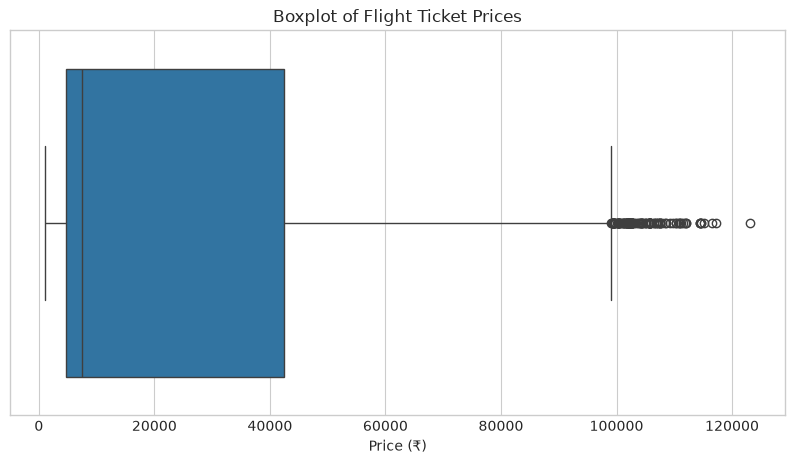

In [32]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["price"])

plt.title("Boxplot of Flight Ticket Prices")
plt.xlabel("Price (₹)")

plt.show()

In [33]:
#Q10. Create a data dictionary
data_dictionary = pd.DataFrame({
    "Feature": [
        "Unnamed: 0",
        "airline",
        "flight",
        "source_city",
        "departure_time",
        "stops",
        "arrival_time",
        "destination_city",
        "class",
        "duration",
        "days_left",
        "price"
    ],

    "Data Type": [
        str(df[col].dtype) for col in [
            "Unnamed: 0", "airline", "flight",
            "source_city", "departure_time", "stops",
            "arrival_time", "destination_city",
            "class", "duration", "days_left", "price"
        ]
    ],

    "Meaning": [
        "Original dataset index",
        "Airline operating the flight",
        "Flight identification number",
        "Departure city",
        "Departure time category",
        "Number of stops",
        "Arrival time category",
        "Destination city",
        "Travel class (Economy or Business)",
        "Total flight duration",
        "Days remaining before departure",
        "Flight ticket price in INR"
    ],

    "Preprocessing Required": [
        "Check and remove if redundant",
        "Check categorical consistency; encode if needed",
        "Assess usefulness; possibly exclude",
        "Standardize and encode",
        "Standardize and encode",
        "Standardize categorical labels",
        "Standardize and encode",
        "Standardize and encode",
        "Encode categorical values",
        "Convert to numerical duration",
        "Check numerical values",
        "Check outliers and invalid prices"
    ]
})

display(data_dictionary)

,Feature,Data Type,Meaning,Preprocessing Required
0,Unnamed: 0,int64,Original dataset index,Check and remove if redundant
1,airline,str,Airline operating the flight,Check categorical consistency; encode if needed
2,flight,str,Flight identification number,Assess usefulness; possibly exclude
3,source_city,str,Departure city,Standardize and encode
4,departure_time,str,Departure time category,Standardize and encode
5,stops,str,Number of stops,Standardize categorical labels
6,arrival_time,str,Arrival time category,Standardize and encode
7,destination_city,str,Destination city,Standardize and encode
8,class,str,Travel class (Economy or Business),Encode categorical values
9,duration,float64,Total flight duration,Convert to numerical duration


In [34]:
#Section B 
# Q11. Calculate mean, median, mode, standard deviation, variance, minimum and maximum of Price.

price = df["price"]

print("Mean:", price.mean())
print("Median:", price.median())
print("Mode:", price.mode().tolist())
print("Standard Deviation:", price.std())
print("Variance:", price.var())
print("Minimum Price:", price.min())
print("Maximum Price:", price.max())

Mean: 20889.660523133203
Median: 7425.0
Mode: [54608]
Standard Deviation: 22697.76736607447
Variance: 515188643.4044351
Minimum Price: 1105
Maximum Price: 123071


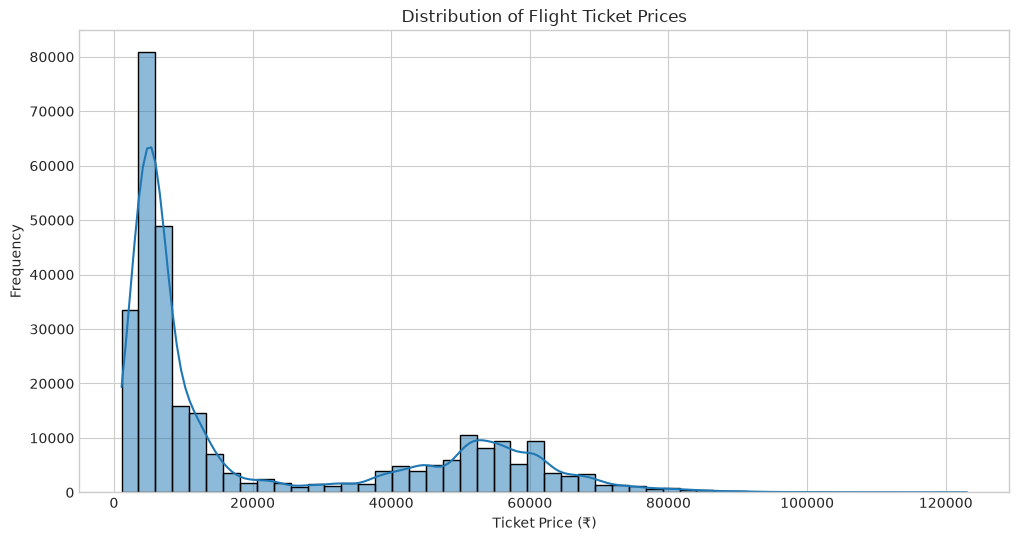

Price Skewness: 1.0613772532064343


In [37]:
#Q12. Plot histogram and KDE curve. Is the distribution normal, positively skewed or negatively skewed?

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="price",
    bins=50,
    kde=True
)

plt.title("Distribution of Flight Ticket Prices")
plt.xlabel("Ticket Price (₹)")
plt.ylabel("Frequency")

plt.show()

print("Price Skewness:", df["price"].skew())

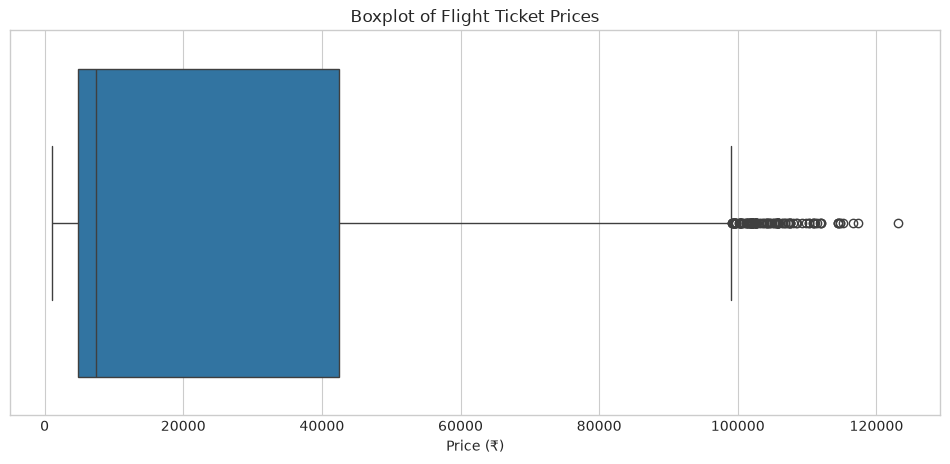

Q1: 4783.0
Q3: 42521.0
IQR: 37738.0
Lower Limit: -51824.0
Upper Limit: 99128.0
Total Outliers: 123
Outlier Percentage: 0.04 %


In [40]:
#Q13. Plot a boxplot of Price. Identify potential outliers using the IQR method.

plt.figure(figsize=(12, 5))

sns.boxplot(x=df["price"])

plt.title("Boxplot of Flight Ticket Prices")
plt.xlabel("Price (₹)")

plt.show()

# Calculate quartiles

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

# Calculate lower and upper limits

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify outliers

outliers = df[
    (df["price"] < lower_limit) |
    (df["price"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

print("Total Outliers:", len(outliers))

print("Outlier Percentage:",
      round(len(outliers) / len(df) * 100, 2), "%")

In [41]:
#Q14. Calculate the 5th, 25th, 50th, 75th, 90th, 95th and 99th percentiles.
# Q14: Calculate price percentiles

percentiles = [5, 25, 50, 75, 90, 95, 99]

price_percentiles = df["price"].quantile(
    [p / 100 for p in percentiles]
)

price_percentiles.index = [
    f"{p}th Percentile" for p in percentiles
]

display(price_percentiles.to_frame(name="Ticket Price (₹)"))

,Ticket Price (₹)
5th Percentile,2436.0
25th Percentile,4783.0
50th Percentile,7425.0
75th Percentile,42521.0
90th Percentile,57920.0
95th Percentile,63277.0
99th Percentile,76736.0


Tickets below ₹3,000: 21,781 (7.26%)
Tickets below ₹5,000: 81,386 (27.11%)
Tickets below ₹10,000: 173,653 (57.85%)
Tickets below ₹20,000: 205,255 (68.38%)


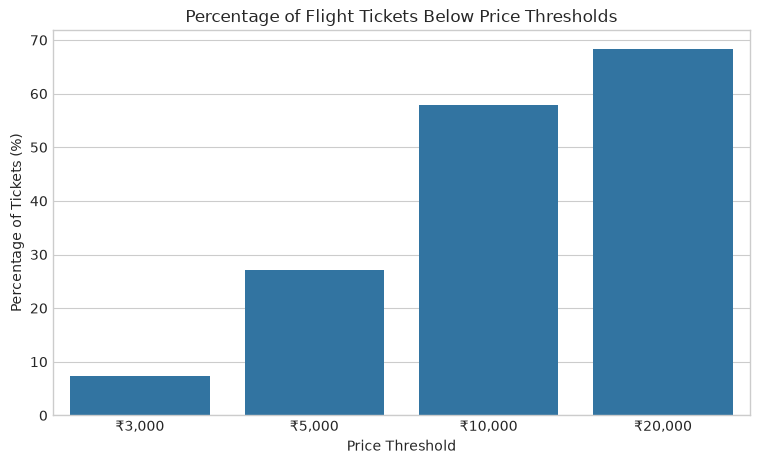

In [46]:
#Q15. What percentage of flight tickets cost less than ₹3,000, ₹5,000, ₹10,000 and ₹20,000?\

thresholds = [3000, 5000, 10000, 20000]

for threshold in thresholds:

    count = (df["price"] < threshold).sum()

    percentage = (count / len(df)) * 100

    print(
        f"Tickets below ₹{threshold:,}: "
        f"{count:,} ({percentage:.2f}%)"
    )

# Prepare percentage data

percentages = [(df["price"] < threshold).mean() * 100 for threshold in thresholds]

plt.figure(figsize=(9, 5))

sns.barplot(
    x=[f"₹{t:,}" for t in thresholds],
    y=percentages
)

plt.title("Percentage of Flight Tickets Below Price Thresholds")
plt.xlabel("Price Threshold")
plt.ylabel("Percentage of Tickets (%)")

plt.show()

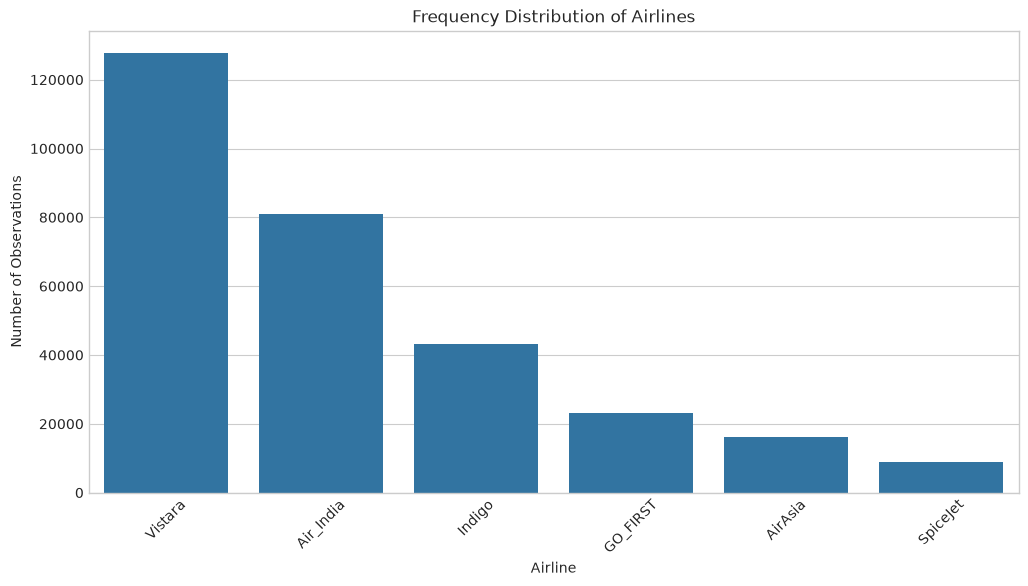

,Frequency
airline,
Vistara,127859
Air_India,80892
Indigo,43120
GO_FIRST,23173
AirAsia,16098
SpiceJet,9011


In [47]:
# Q16. Plot the frequency distribution of airlines. Which airlines have the highest number of observations?

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="airline",
    order=df["airline"].value_counts().index
)

plt.title("Frequency Distribution of Airlines")
plt.xlabel("Airline")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45)

plt.show()

# Display airline-wise frequency
display(df["airline"].value_counts().to_frame("Frequency"))

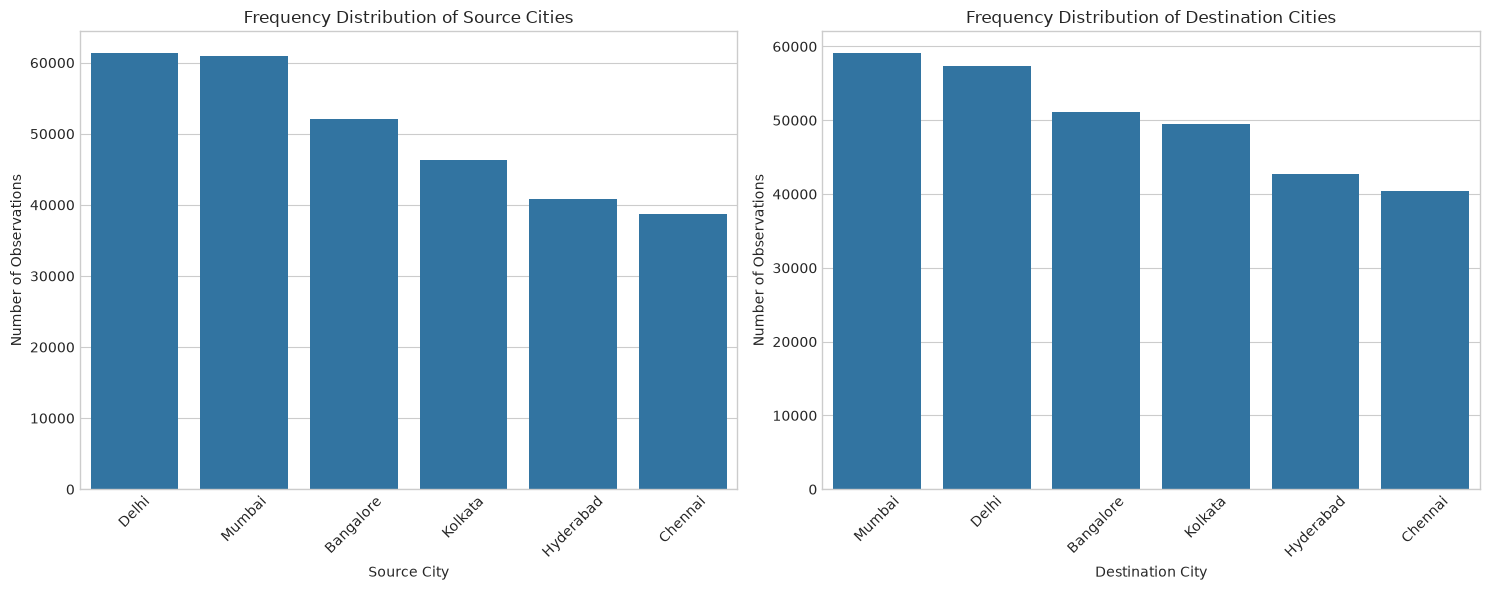

Source City Frequencies:


source_city
Delhi        61343
Mumbai       60896
Bangalore    52061
Kolkata      46347
Hyderabad    40806
Chennai      38700
Name: count, dtype: int64

Destination City Frequencies:


destination_city
Mumbai       59097
Delhi        57360
Bangalore    51068
Kolkata      49534
Hyderabad    42726
Chennai      40368
Name: count, dtype: int64

In [48]:
# Q17. Plot the frequency distribution of source and destination cities. Are all cities represented equally?

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Source city distribution
sns.countplot(
    data=df,
    x="source_city",
    order=df["source_city"].value_counts().index,
    ax=axes[0]
)

axes[0].set_title("Frequency Distribution of Source Cities")
axes[0].set_xlabel("Source City")
axes[0].set_ylabel("Number of Observations")
axes[0].tick_params(axis="x", rotation=45)

# Destination city distribution
sns.countplot(
    data=df,
    x="destination_city",
    order=df["destination_city"].value_counts().index,
    ax=axes[1]
)

axes[1].set_title("Frequency Distribution of Destination Cities")
axes[1].set_xlabel("Destination City")
axes[1].set_ylabel("Number of Observations")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Display city frequencies
print("Source City Frequencies:")
display(df["source_city"].value_counts())

print("Destination City Frequencies:")
display(df["destination_city"].value_counts())

,Frequency,Percentage
stops,,
one,250863,83.58
zero,36004,12.00
two_or_more,13286,4.43


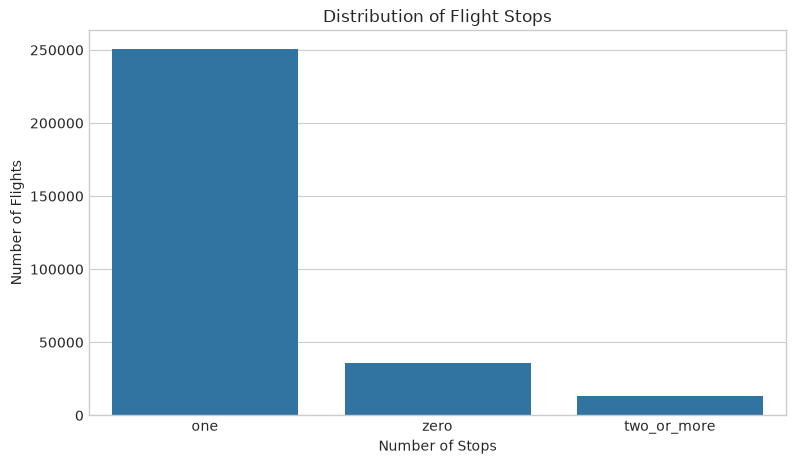

In [49]:
# Q18. Analyse the distribution of Stops. What percentage of flights are non-stop, one-stop and multi-stop?

# Calculate frequency and percentage
stops_frequency = df["stops"].value_counts()

stops_percentage = (
    df["stops"].value_counts(normalize=True) * 100
)

stops_summary = pd.DataFrame({
    "Frequency": stops_frequency,
    "Percentage": stops_percentage.round(2)
})

display(stops_summary)

# Plot distribution of stops
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="stops",
    order=df["stops"].value_counts().index
)

plt.title("Distribution of Flight Stops")
plt.xlabel("Number of Stops")
plt.ylabel("Number of Flights")

plt.show()

Duration Data Type: float64
Shortest Flight Duration: 0.83 hours
Longest Flight Duration: 49.83 hours
Median Flight Duration: 11.25 hours
Average Flight Duration: 12.221020812718846 hours


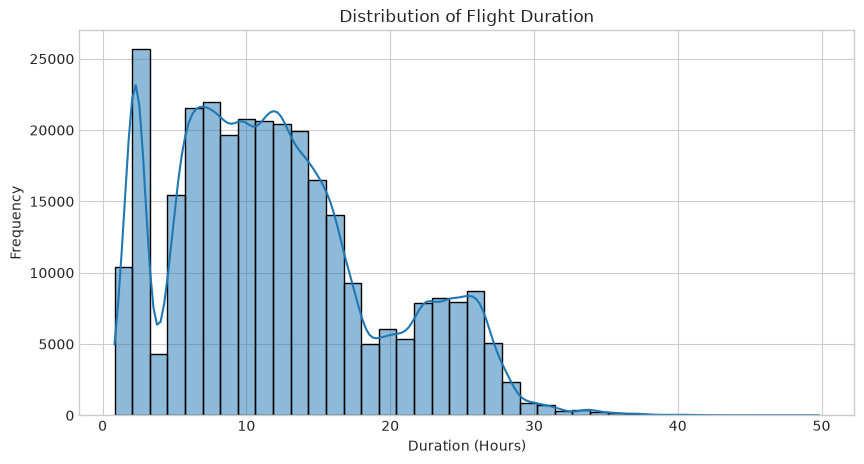

In [52]:
# Q19. Analyse Duration. What are the shortest, longest, median and average flight durations?

print("Duration Data Type:", df["duration"].dtype)

# Calculate duration statistics
print("Shortest Flight Duration:", df["duration"].min(), "hours")
print("Longest Flight Duration:", df["duration"].max(), "hours")
print("Median Flight Duration:", df["duration"].median(), "hours")
print("Average Flight Duration:", df["duration"].mean(), "hours")

# Plot the distribution of flight duration

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="duration",
    bins=40,
    kde=True
)

plt.title("Distribution of Flight Duration")
plt.xlabel("Duration (Hours)")
plt.ylabel("Frequency")

plt.show()

count    300153.000000
mean         26.004751
std          13.561004
min           1.000000
25%          15.000000
50%          26.000000
75%          38.000000
max          49.000000
Name: days_left, dtype: float64

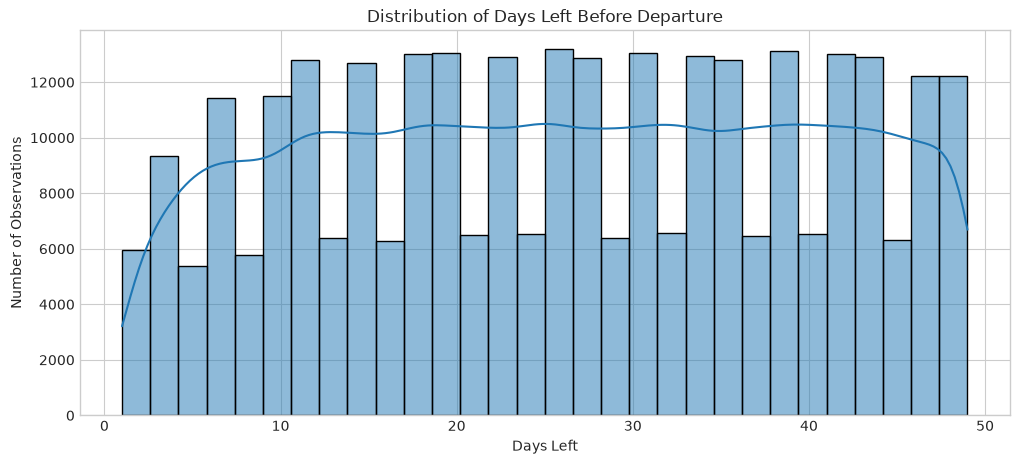

,Number of Observations
days_left,
1,1927
2,4026
3,4248
4,5077
5,5392
6,5740
7,5703
8,5767
9,5665


In [54]:
# Q20. Analyse Days Left. Are booking observations concentrated close to departure. 
# or spread across the entire booking window?

# Calculate descriptive statistics
display(df["days_left"].describe())

# Frequency distribution of Days Left
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="days_left",
    bins=30,
    kde=True
)

plt.title("Distribution of Days Left Before Departure")
plt.xlabel("Days Left")
plt.ylabel("Number of Observations")

plt.show()

# Count observations for each booking window
days_frequency = df["days_left"].value_counts().sort_index()

display(days_frequency.to_frame("Number of Observations"))

In [55]:
# Section C
# Q21. Calculate the mean, median, minimum and maximum fare. for every airline. Which airline has the highest median fare?

airline_fares = df.groupby("airline")["price"].agg(
    Mean_Fare="mean",
    Median_Fare="median",
    Minimum_Fare="min",
    Maximum_Fare="max"
).round(2)

display(airline_fares.sort_values("Median_Fare", ascending=False))

# Airline with the highest median fare
highest_median_airline = airline_fares["Median_Fare"].idxmax()

print("Airline with highest median fare:", highest_median_airline)
print("Highest median fare:",
      airline_fares["Median_Fare"].max())

,Mean_Fare,Median_Fare,Minimum_Fare,Maximum_Fare
airline,,,,
Vistara,30396.54,15543.0,1714,123071
Air_India,23507.02,11520.0,1526,90970
SpiceJet,6179.28,5654.0,1106,34158
GO_FIRST,5652.01,5336.0,1105,32803
Indigo,5324.22,4453.0,1105,31952
AirAsia,4091.07,3276.0,1105,31917


Airline with highest median fare: Vistara
Highest median fare: 15543.0


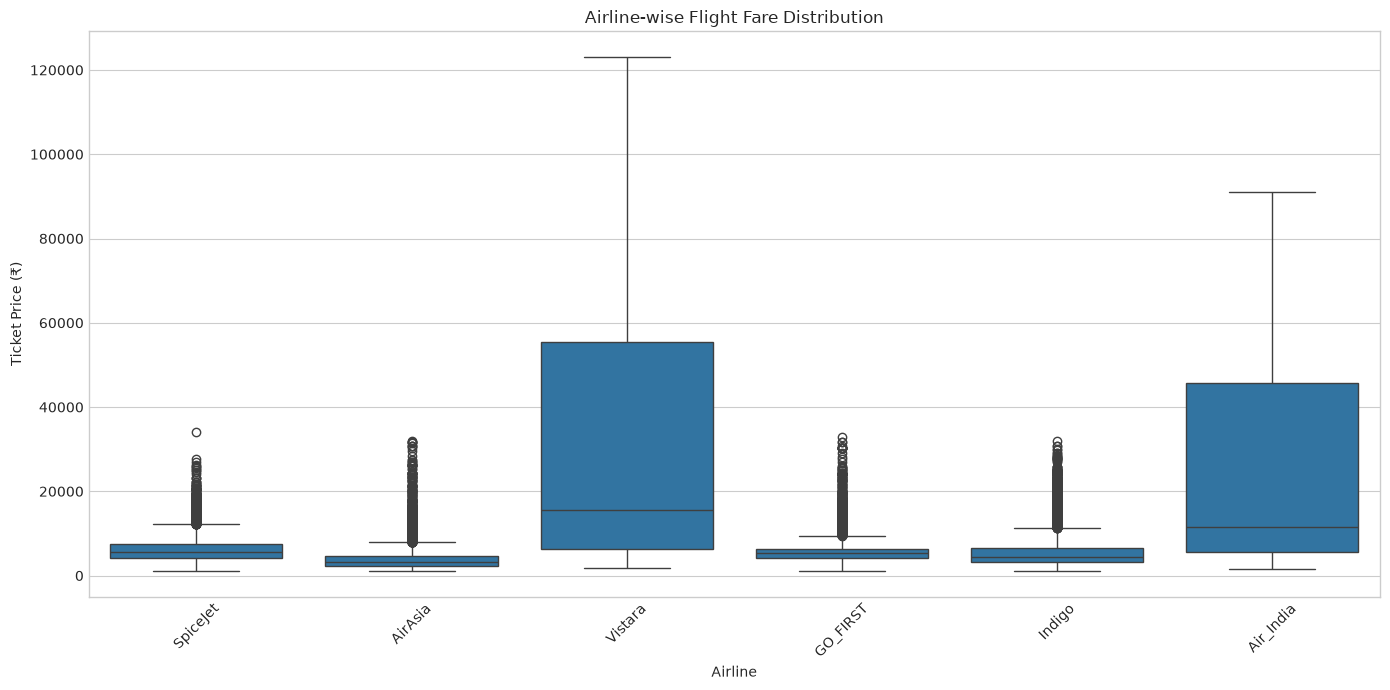

Airline-wise fare variation (Standard Deviation):


,Standard Deviation
airline,
Vistara,25637.159445
Air_India,20905.116909
Indigo,3268.894831
SpiceJet,2999.630406
AirAsia,2824.055172
GO_FIRST,2513.865560


Airline with largest fare variation: Vistara


In [56]:
# Q22. Plot airline-wise fare distributions using boxplots.
# Which airline has the largest fare variation?

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="airline",
    y="price"
)

plt.title("Airline-wise Flight Fare Distribution")
plt.xlabel("Airline")
plt.ylabel("Ticket Price (₹)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Calculate fare variation using standard deviation
airline_variation = df.groupby("airline")["price"].std().sort_values(
    ascending=False
)

print("Airline-wise fare variation (Standard Deviation):")
display(airline_variation.to_frame("Standard Deviation"))

print("Airline with largest fare variation:",
      airline_variation.idxmax())

In [57]:
# Q23. Rank airlines based on median ticket price.
# Does the ranking change when airlines are ranked using mean price?

airline_ranking = df.groupby("airline")["price"].agg(
    Mean_Fare="mean",
    Median_Fare="median"
)

# Rank airlines from lowest to highest fare
airline_ranking["Median Rank"] = airline_ranking[
    "Median_Fare"
].rank(method="min").astype(int)

airline_ranking["Mean Rank"] = airline_ranking[
    "Mean_Fare"
].rank(method="min").astype(int)

airline_ranking = airline_ranking.sort_values("Median Rank")

display(airline_ranking.round(2))

,Mean_Fare,Median_Fare,Median Rank,Mean Rank
airline,,,,
AirAsia,4091.07,3276.0,1,1
Indigo,5324.22,4453.0,2,2
GO_FIRST,5652.01,5336.0,3,3
SpiceJet,6179.28,5654.0,4,4
Air_India,23507.02,11520.0,5,5
Vistara,30396.54,15543.0,6,6


In [58]:
# Q24. Calculate the number of flights operated by each airline
# in the dataset. Is the airline with the highest number of
# records also the cheapest?

airline_flight_count = df["airline"].value_counts()

airline_summary = df.groupby("airline")["price"].agg(
    Mean_Fare="mean",
    Median_Fare="median"
)

airline_summary["Flight Records"] = airline_flight_count

airline_summary = airline_summary.sort_values(
    "Flight Records",
    ascending=False
)

display(airline_summary.round(2))

# Airline with highest number of records
most_observed_airline = airline_summary["Flight Records"].idxmax()

# Airline with lowest median fare
cheapest_airline = airline_summary["Median_Fare"].idxmin()

print("Airline with highest records:", most_observed_airline)
print("Airline with lowest median fare:", cheapest_airline)

print("Are they the same?:",
      most_observed_airline == cheapest_airline)

,Mean_Fare,Median_Fare,Flight Records
airline,,,
Vistara,30396.54,15543.0,127859
Air_India,23507.02,11520.0,80892
Indigo,5324.22,4453.0,43120
GO_FIRST,5652.01,5336.0,23173
AirAsia,4091.07,3276.0,16098
SpiceJet,6179.28,5654.0,9011


Airline with highest records: Vistara
Airline with lowest median fare: AirAsia
Are they the same?: False


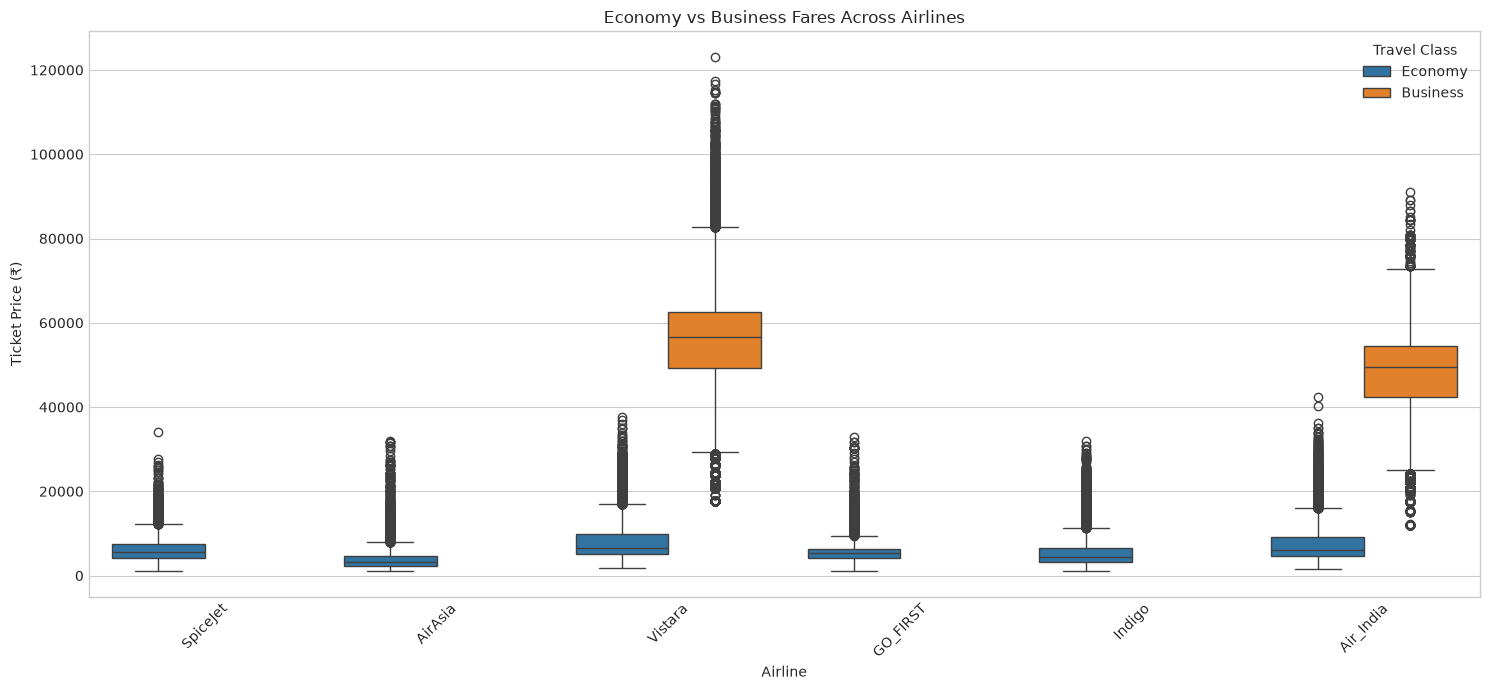

class,Business,Economy
airline,,
AirAsia,NaN,3276.0
Air_India,49613.0,6082.0
GO_FIRST,NaN,5336.0
Indigo,NaN,4453.0
SpiceJet,NaN,5654.0
Vistara,56588.0,6461.0


class,Business,Economy,Fare Gap
airline,,,
Vistara,56588.0,6461.0,50127.0
Air_India,49613.0,6082.0,43531.0
AirAsia,NaN,3276.0,NaN
GO_FIRST,NaN,5336.0,NaN
Indigo,NaN,4453.0,NaN
SpiceJet,NaN,5654.0,NaN


In [59]:
# Q25. Compare the distribution of Economy and Business fares
# for every airline. Does the class-wise fare gap differ across airlines?

plt.figure(figsize=(15, 7))

sns.boxplot(
    data=df,
    x="airline",
    y="price",
    hue="class"
)

plt.title("Economy vs Business Fares Across Airlines")
plt.xlabel("Airline")
plt.ylabel("Ticket Price (₹)")
plt.xticks(rotation=45)
plt.legend(title="Travel Class")

plt.tight_layout()
plt.show()

# Calculate median fare by airline and class
class_fares = df.groupby(
    ["airline", "class"]
)["price"].median().unstack()

display(class_fares)

# Calculate class-wise median fare gap
class_fares["Fare Gap"] = (
    class_fares["Business"] - class_fares["Economy"]
)

display(class_fares.sort_values("Fare Gap", ascending=False))

In [60]:
# Q26. Identify the cheapest and most expensive airline for each
# source-destination combination. Compare only routes with
# sufficient observations.

# Create route column
df["Route"] = (
    df["source_city"] + " to " + df["destination_city"]
)

# Calculate airline-wise route statistics
route_airline = df.groupby(
    ["Route", "airline"]
)["price"].agg(["median", "count"]).reset_index()

# Retain combinations with at least 30 observations
route_airline = route_airline[
    route_airline["count"] >= 30
]

# Find cheapest and most expensive airlines for each route
cheapest = route_airline.loc[
    route_airline.groupby("Route")["median"].idxmin()
].copy()

expensive = route_airline.loc[
    route_airline.groupby("Route")["median"].idxmax()
].copy()

# Prepare comparison table
route_comparison = pd.DataFrame({
    "Cheapest Airline": cheapest.set_index("Route")["airline"],
    "Cheapest Median Fare": cheapest.set_index("Route")["median"],
    "Most Expensive Airline": expensive.set_index("Route")["airline"],
    "Most Expensive Median Fare": expensive.set_index("Route")["median"]
})

display(route_comparison.round(2))

,Cheapest Airline,Cheapest Median Fare,Most Expensive Airline,Most Expensive Median Fare
Route,,,,
Bangalore to Chennai,AirAsia,1715.0,Air_India,13316.5
Bangalore to Delhi,AirAsia,3467.0,Vistara,32923.0
Bangalore to Hyderabad,AirAsia,1714.0,Vistara,14150.0
Bangalore to Kolkata,AirAsia,3393.0,Vistara,51817.0
Bangalore to Mumbai,AirAsia,2203.0,Vistara,20760.0
Chennai to Bangalore,AirAsia,1548.0,Vistara,15439.0
Chennai to Delhi,AirAsia,2477.0,Vistara,16140.0
Chennai to Hyderabad,GO_FIRST,1105.0,Vistara,15563.0
Chennai to Kolkata,AirAsia,2361.0,Air_India,15963.0


In [61]:
# Q27. Calculate the percentage of each airline's records
# that fall below the overall median fare.
# Which airlines have the highest proportion of relatively
# inexpensive tickets?

overall_median = df["price"].median()

airline_affordability = df.groupby("airline").agg(
    Total_Records=("price", "count"),
    Records_Below_Median=(
        "price",
        lambda x: (x < overall_median).sum()
    )
)

airline_affordability["Percentage_Below_Median"] = (
    airline_affordability["Records_Below_Median"] /
    airline_affordability["Total_Records"] * 100
)

airline_affordability = airline_affordability.sort_values(
    "Percentage_Below_Median",
    ascending=False
)

print("Overall median fare:", overall_median)

display(airline_affordability.round(2))

Overall median fare: 7425.0


,Total_Records,Records_Below_Median,Percentage_Below_Median
airline,,,
AirAsia,16098,14677,91.17
GO_FIRST,23173,20322,87.70
Indigo,43120,34990,81.15
SpiceJet,9011,6829,75.79
Air_India,80892,32115,39.70
Vistara,127859,40581,31.74


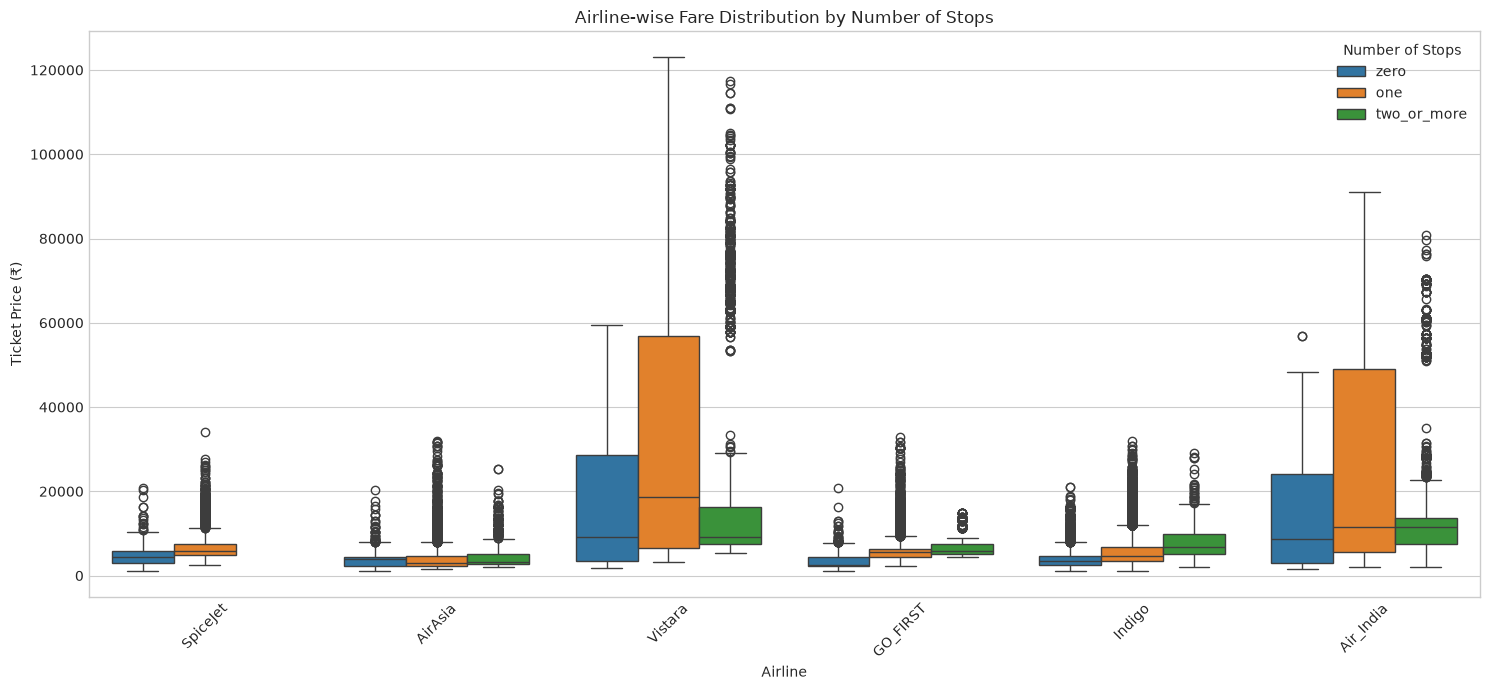

median      mean   count
airline   stops                                 
AirAsia   one           3090.0   4096.96   11418
          two_or_more   3175.0   4432.96    2246
          zero          3862.0   3747.96    2434
Air_India one          11561.0  24805.78   71004
          two_or_more  11545.0  13771.18    3479
          zero          8778.0  14403.19    6409
GO_FIRST  one           5699.0   5972.27   19545
          two_or_more   5954.0   7107.71     405
          zero          2410.0   3526.92    3223
Indigo    one           4748.0   5733.03   31166
          two_or_more   6858.0   7834.84     738
          zero          3551.0   4023.05   11216
SpiceJet  one           5954.0   6789.36    6549
          zero          4499.0   4556.43    2462
Vistara   one          18566.0  32353.15  111181
          two_or_more   9111.5  18850.77    6418
          zero          9243.0  16416.27   10260

In [62]:
# Q28. Investigate whether an airline's fare distribution
# changes with the number of stops.
# For example, compare non-stop and one-stop fares
# within the same airline.

plt.figure(figsize=(15, 7))

sns.boxplot(
    data=df,
    x="airline",
    y="price",
    hue="stops"
)

plt.title("Airline-wise Fare Distribution by Number of Stops")
plt.xlabel("Airline")
plt.ylabel("Ticket Price (₹)")
plt.xticks(rotation=45)
plt.legend(title="Number of Stops")

plt.tight_layout()
plt.show()

# Calculate median fare by airline and stops
stop_fares = df.groupby(
    ["airline", "stops"]
)["price"].agg(["median", "mean", "count"])

display(stop_fares.round(2))

In [63]:
# Section FD
# Q29. Find the number of unique source-destination combinations.
# How many observations exist for each route?

# Count observations for every source-destination combination
route_counts = df.groupby(
    ["source_city", "destination_city"]
).size().reset_index(name="Observations")

# Count unique routes
unique_routes = route_counts.shape[0]

print("Number of unique source-destination combinations:",
      unique_routes)

# Display observations for each route
display(route_counts.sort_values(
    "Observations", ascending=False
))

Number of unique source-destination combinations: 30


,source_city,destination_city,Observations
14,Delhi,Mumbai,15289
27,Mumbai,Delhi,14809
10,Delhi,Bangalore,14012
1,Bangalore,Delhi,13756
4,Bangalore,Mumbai,12939
25,Mumbai,Bangalore,12885
29,Mumbai,Kolkata,12602
13,Delhi,Kolkata,11934
24,Kolkata,Mumbai,11467
11,Delhi,Chennai,10780


In [64]:
# Q30. Create a route column by combining source and destination,
# for example: Delhi -> Mumbai.

df["Route_City"] = (
    df["source_city"] + " -> " + df["destination_city"]
)

# Display sample routes
display(df[[
    "source_city",
    "destination_city",
    "Route_City"
]].head(10))

,source_city,destination_city,Route_City
0,Delhi,Mumbai,Delhi -> Mumbai
1,Delhi,Mumbai,Delhi -> Mumbai
2,Delhi,Mumbai,Delhi -> Mumbai
3,Delhi,Mumbai,Delhi -> Mumbai
4,Delhi,Mumbai,Delhi -> Mumbai
5,Delhi,Mumbai,Delhi -> Mumbai
6,Delhi,Mumbai,Delhi -> Mumbai
7,Delhi,Mumbai,Delhi -> Mumbai
8,Delhi,Mumbai,Delhi -> Mumbai
9,Delhi,Mumbai,Delhi -> Mumbai


In [65]:
# Q31. Create a route feature by combining origin and destination
# for route analysis.

df["Route"] = (
    df["source_city"] + " - " + df["destination_city"]
)

print("Route feature created successfully!")

display(df[["Route"]].head(10))

Route feature created successfully!


,Route
0,Delhi - Mumbai
1,Delhi - Mumbai
2,Delhi - Mumbai
3,Delhi - Mumbai
4,Delhi - Mumbai
5,Delhi - Mumbai
6,Delhi - Mumbai
7,Delhi - Mumbai
8,Delhi - Mumbai
9,Delhi - Mumbai


In [66]:
# Q32. Calculate the average and median fare for every route.
# Which routes have the highest and lowest median prices?

route_fares = df.groupby("Route")["price"].agg(
    Average_Fare="mean",
    Median_Fare="median",
    Observations="count"
).round(2)

# Sort routes by median fare
route_fares_sorted = route_fares.sort_values(
    "Median_Fare",
    ascending=False
)

print("Routes with highest median fares:")
display(route_fares_sorted.head(10))

print("Routes with lowest median fares:")
display(route_fares_sorted.tail(10))

Routes with highest median fares:


,Average_Fare,Median_Fare,Observations
Route,,,
Chennai - Bangalore,25081.85,10469.0,6493
Bangalore - Chennai,23321.85,9241.0,6410
Kolkata - Chennai,23660.36,8589.0,6653
Kolkata - Hyderabad,21500.01,8467.0,7897
Chennai - Kolkata,22669.93,8394.0,6983
Chennai - Mumbai,22765.85,8233.0,9338
Mumbai - Chennai,22781.90,8148.0,10130
Bangalore - Kolkata,23500.06,8112.0,10028
Kolkata - Bangalore,22744.81,8111.0,9824


Routes with lowest median fares:


,Average_Fare,Median_Fare,Observations
Route,,,
Bangalore - Delhi,17723.31,7164.0,13756
Bangalore - Mumbai,23128.62,7113.0,12939
Hyderabad - Bangalore,21347.18,7091.0,7854
Delhi - Kolkata,20566.41,7084.0,11934
Kolkata - Delhi,19422.35,6723.0,10506
Delhi - Bangalore,17880.22,6642.0,14012
Hyderabad - Mumbai,20080.87,6633.0,10064
Mumbai - Delhi,18725.32,6300.0,14809
Hyderabad - Delhi,17243.95,6138.0,8506


In [67]:
# Q33. Are fares from Delhi to Mumbai similar to fares
# from Mumbai to Delhi? Compare both directions.

delhi_mumbai = df[
    (df["source_city"] == "Delhi") &
    (df["destination_city"] == "Mumbai")
]["price"]

mumbai_delhi = df[
    (df["source_city"] == "Mumbai") &
    (df["destination_city"] == "Delhi")
]["price"]

# Compare fare statistics
direction_comparison = pd.DataFrame({
    "Delhi to Mumbai": delhi_mumbai.describe(),
    "Mumbai to Delhi": mumbai_delhi.describe()
})

display(direction_comparison.round(2))

print("Median fare difference:",
      abs(delhi_mumbai.median() - mumbai_delhi.median()))

,Delhi to Mumbai,Mumbai to Delhi
count,15289.00,14809.00
mean,19355.83,18725.32
std,19777.25,19493.52
min,2281.00,2336.00
25%,4381.00,4221.00
50%,7262.00,6300.00
75%,36712.00,36565.00
max,95657.00,111437.00


Median fare difference: 962.0


In [68]:
# Q34. Create a pivot table with source cities as rows,
# destination cities as columns and median ticket prices as values.

route_pivot = pd.pivot_table(
    df,
    values="price",
    index="source_city",
    columns="destination_city",
    aggfunc="median"
)

display(route_pivot.round(2))

destination_city,Bangalore,Chennai,Delhi,Hyderabad,Kolkata,Mumbai
source_city,,,,,,
Bangalore,NaN,9241.0,7164.0,7813.0,8112.0,7113.0
Chennai,10469.0,NaN,7352.0,7373.0,8394.0,8233.0
Delhi,6642.0,7425.0,NaN,6109.0,7084.0,7262.0
Hyderabad,7091.0,7702.0,6138.0,NaN,7767.0,6633.0
Kolkata,8111.0,8589.0,6723.0,8467.0,NaN,7958.0
Mumbai,7192.0,8148.0,6300.0,7584.0,7518.0,NaN


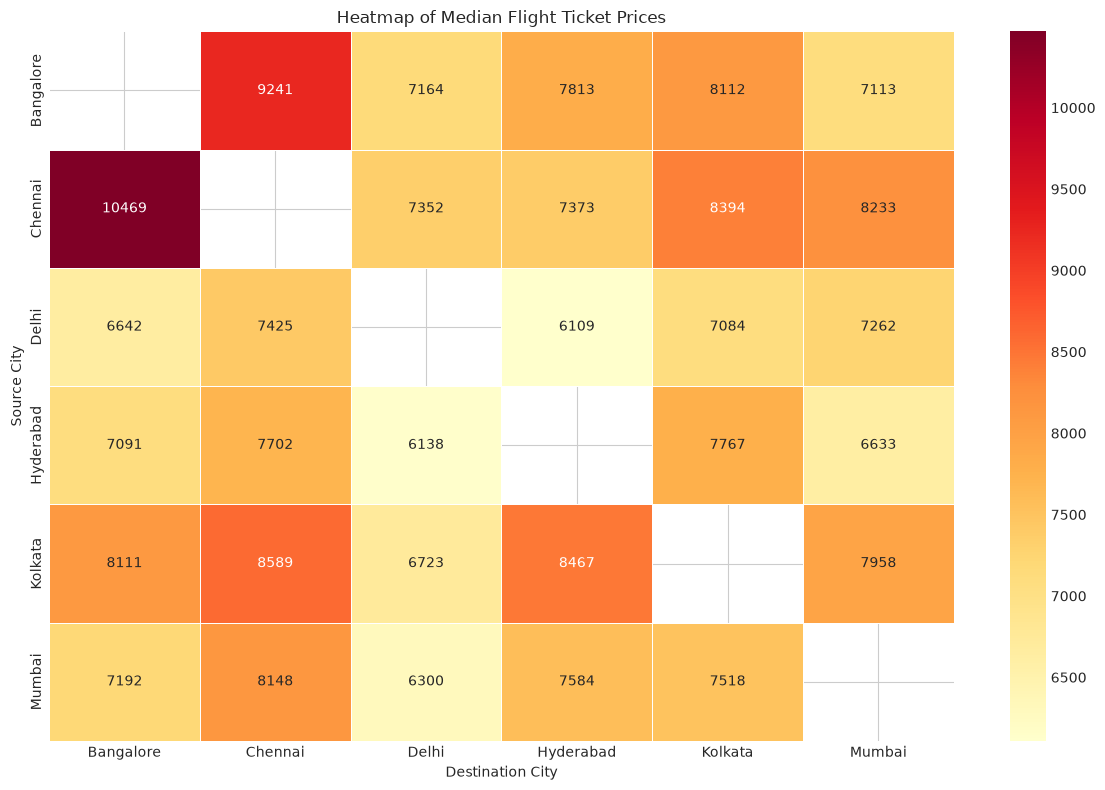

In [69]:
# Q35. Plot a heatmap of median ticket prices for all
# source-destination combinations.
# Which city pairs have relatively high or low fares?

plt.figure(figsize=(12, 8))

sns.heatmap(
    route_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Heatmap of Median Flight Ticket Prices")
plt.xlabel("Destination City")
plt.ylabel("Source City")

plt.tight_layout()
plt.show()

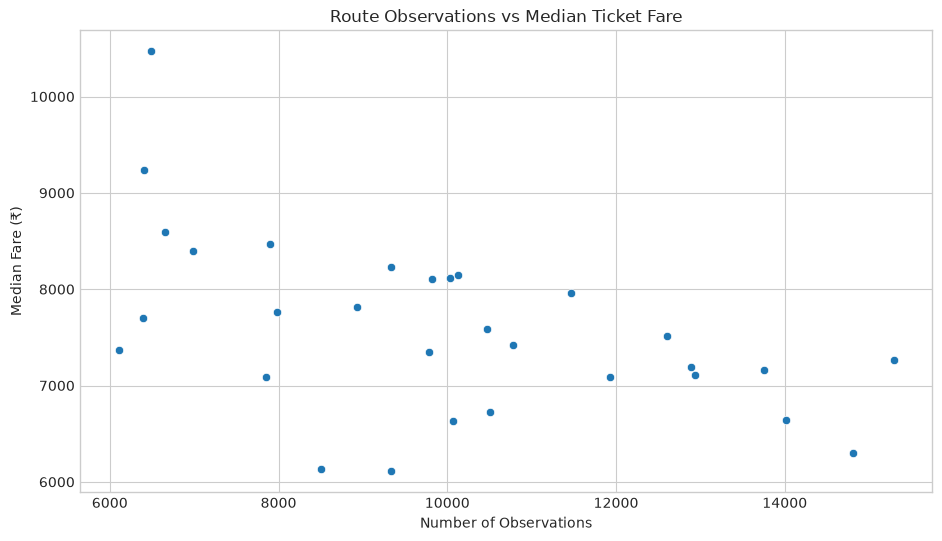

Correlation between observations and median fare: -0.523


In [70]:
# Q36. Compare the number of available flights against median fare
# for each route. Do routes with more observations tend to
# have lower prices?

route_analysis = df.groupby("Route")["price"].agg(
    Median_Fare="median",
    Observations="count"
).reset_index()

# Scatter plot
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=route_analysis,
    x="Observations",
    y="Median_Fare"
)

plt.title("Route Observations vs Median Ticket Fare")
plt.xlabel("Number of Observations")
plt.ylabel("Median Fare (₹)")

plt.show()

# Calculate correlation
correlation = route_analysis[
    ["Observations", "Median_Fare"]
].corr().iloc[0, 1]

print("Correlation between observations and median fare:",
      round(correlation, 3))

In [71]:
# Q37. For every route, identify the cheapest airline and
# compare its median price against the route-wide median.

# Calculate median price by route and airline
route_airline_fares = df.groupby(
    ["Route", "airline"]
)["price"].median().reset_index()

route_airline_fares.rename(
    columns={"price": "Airline_Median_Fare"},
    inplace=True
)

# Identify cheapest airline for every route
cheapest_airlines = route_airline_fares.loc[
    route_airline_fares.groupby("Route")[
        "Airline_Median_Fare"
    ].idxmin()
].copy()

# Calculate route-wide median
route_wide_median = df.groupby("Route")["price"].median()

cheapest_airlines["Route_Wide_Median"] = (
    cheapest_airlines["Route"].map(route_wide_median)
)

cheapest_airlines["Fare_Difference"] = (
    cheapest_airlines["Airline_Median_Fare"] -
    cheapest_airlines["Route_Wide_Median"]
)

display(cheapest_airlines.sort_values("Route"))

,Route,airline,Airline_Median_Fare,Route_Wide_Median,Fare_Difference
0,Bangalore - Chennai,AirAsia,1715.0,9241.0,-7526.0
6,Bangalore - Delhi,AirAsia,3467.0,7164.0,-3697.0
12,Bangalore - Hyderabad,AirAsia,1714.0,7813.0,-6099.0
18,Bangalore - Kolkata,AirAsia,3393.0,8112.0,-4719.0
24,Bangalore - Mumbai,AirAsia,2203.0,7113.0,-4910.0
30,Chennai - Bangalore,AirAsia,1548.0,10469.0,-8921.0
36,Chennai - Delhi,AirAsia,2477.0,7352.0,-4875.0
44,Chennai - Hyderabad,GO_FIRST,1105.0,7373.0,-6268.0
48,Chennai - Kolkata,AirAsia,2361.0,8394.0,-6033.0
54,Chennai - Mumbai,AirAsia,1830.0,8233.0,-6403.0


,Route,stops,Median_Fare,Mean_Fare,Observations
0,Bangalore - Chennai,one,10893.0,25679.430625,5427
1,Bangalore - Chennai,two_or_more,11637.0,17917.648111,503
2,Bangalore - Chennai,zero,1822.0,2329.608333,480
3,Bangalore - Delhi,one,7484.0,18854.887192,11329
4,Bangalore - Delhi,two_or_more,2723.0,4514.856481,216
...,...,...,...,...,...
85,Mumbai - Hyderabad,two_or_more,6401.0,8912.301493,335
86,Mumbai - Hyderabad,zero,3450.0,7232.047865,773
87,Mumbai - Kolkata,one,8059.0,23892.327351,10921
88,Mumbai - Kolkata,two_or_more,8382.0,14888.688503,748


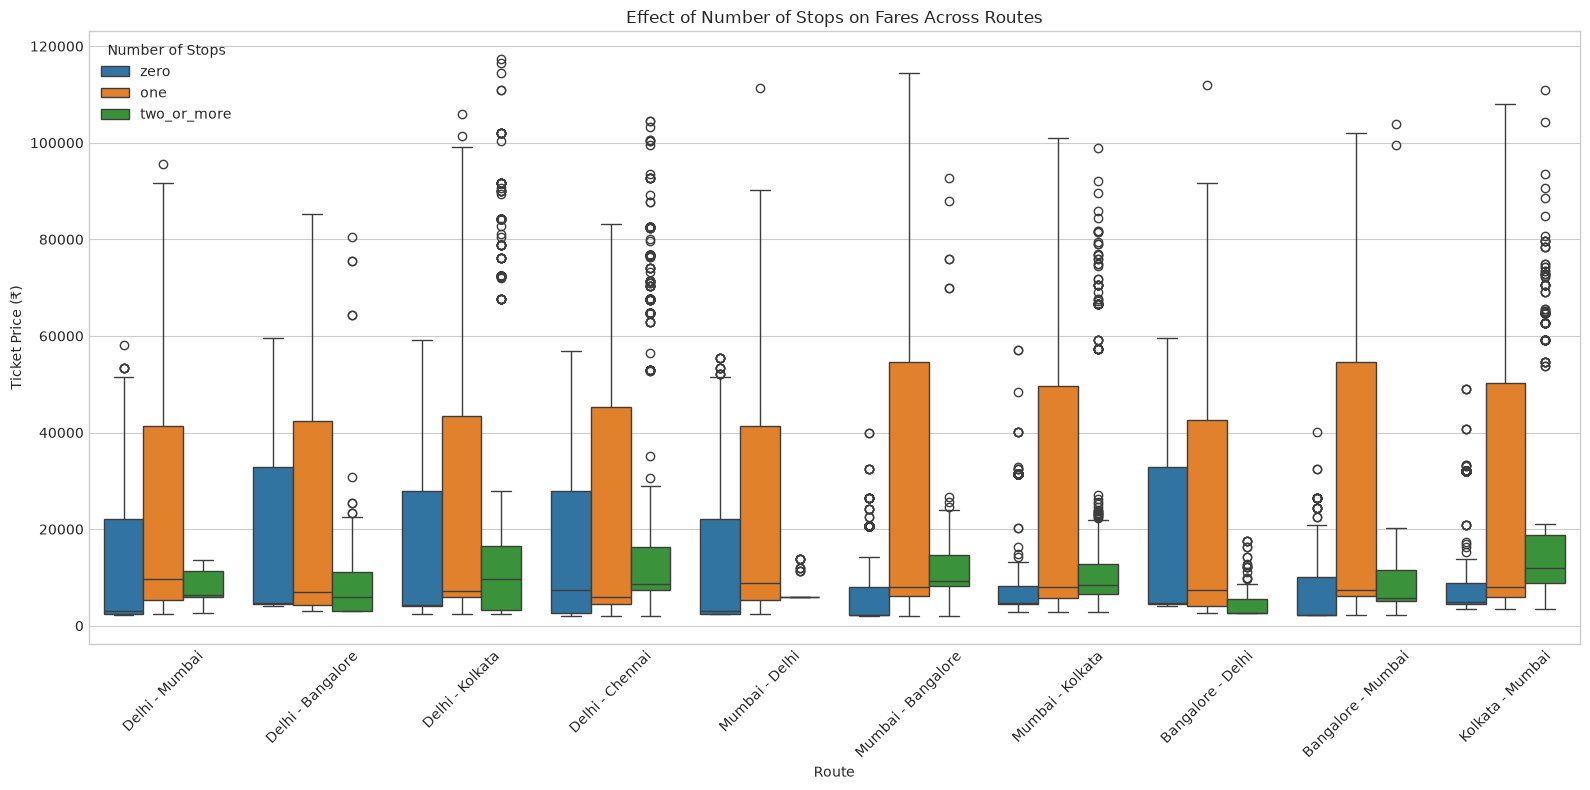

In [73]:
# Q38. Investigate whether the effect of stops on price
# is different for different routes. 

# Calculate median fares by route and number of stops
route_stop_analysis = df.groupby(
    ["Route", "stops"]
)["price"].agg(
    Median_Fare="median",
    Mean_Fare="mean",
    Observations="count"
).reset_index()

display(route_stop_analysis)

# Select the 10 routes with the highest number of observations
top_routes = df["Route"].value_counts().head(10).index

filtered_data = df[df["Route"].isin(top_routes)]

# Compare stop-wise fares for selected routes
plt.figure(figsize=(16, 8))

sns.boxplot(
    data=filtered_data,
    x="Route",
    y="price",
    hue="stops"
)

plt.title("Effect of Number of Stops on Fares Across Routes")
plt.xlabel("Route")
plt.ylabel("Ticket Price (₹)")
plt.xticks(rotation=45)
plt.legend(title="Number of Stops")

plt.tight_layout()
plt.show()

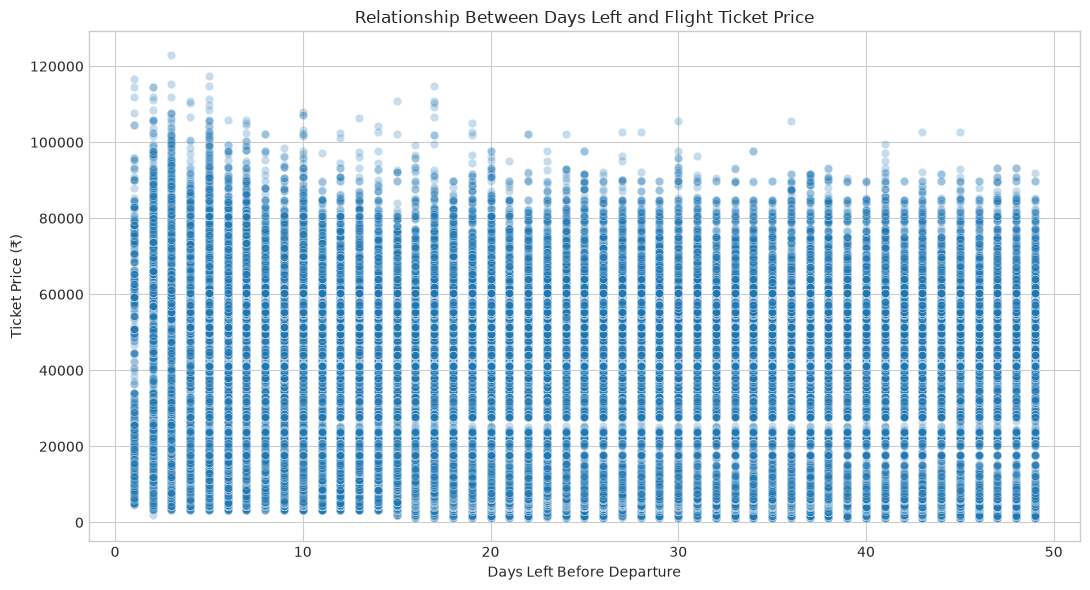

Correlation between Days Left and Price: -0.092


In [74]:
# Section E
# Q38. Plot a scatter plot of Days Left against Price.
# Does the relationship appear linear, nonlinear or highly scattered?
#Again Q38 and we doing it.

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df,
    x="days_left",
    y="price",
    alpha=0.25
)

plt.title("Relationship Between Days Left and Flight Ticket Price")
plt.xlabel("Days Left Before Departure")
plt.ylabel("Ticket Price (₹)")

plt.tight_layout()
plt.show()

# Calculate correlation
correlation = df["days_left"].corr(df["price"])

print("Correlation between Days Left and Price:", round(correlation, 3))

,days_left,Mean_Price,Median_Price
0,1,21591.87,15163.0
1,2,30211.30,18017.5
2,3,28976.08,16333.0
3,4,25730.91,13054.0
4,5,26679.77,13054.0
5,6,24856.49,12417.5
6,7,25588.37,12990.0
7,8,24895.88,12658.0
8,9,25726.25,13947.0
9,10,25572.82,13303.0


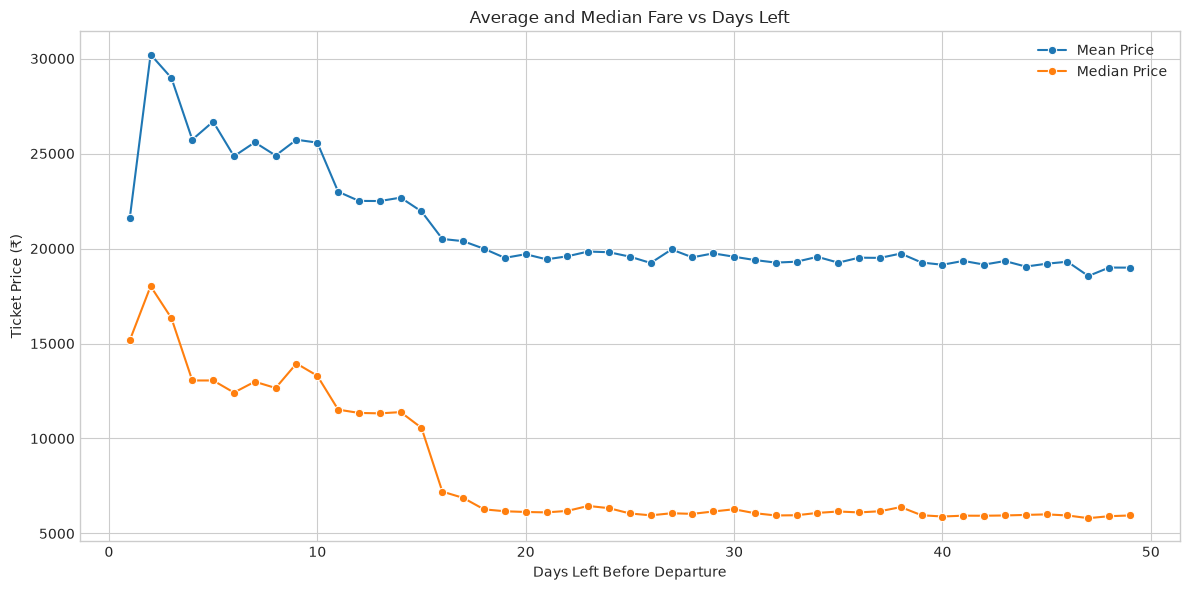

In [75]:
# Q39. Calculate the mean and median price for every value
# of Days Left. Plot how these values change as departure approaches.

days_price = df.groupby("days_left")["price"].agg(
    Mean_Price="mean",
    Median_Price="median"
).reset_index()

display(days_price.round(2))

# Plot mean and median prices
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=days_price,
    x="days_left",
    y="Mean_Price",
    label="Mean Price",
    marker="o"
)

sns.lineplot(
    data=days_price,
    x="days_left",
    y="Median_Price",
    label="Median Price",
    marker="o"
)

plt.title("Average and Median Fare vs Days Left")
plt.xlabel("Days Left Before Departure")
plt.ylabel("Ticket Price (₹)")
plt.legend()

plt.tight_layout()
plt.show()

,Average_Fare,Median_Fare,Observations
Booking_Window,,,
0-3 days,28068.68,16572.0,10201
4-7 days,25698.24,12978.0,21912
8-15 days,23534.11,11893.0,49145
16-30 days,19754.19,6228.5,97234
31-45 days,19335.68,6056.0,97200
46-60 days,18963.83,5896.0,24461
More than 60 days,NaN,NaN,0


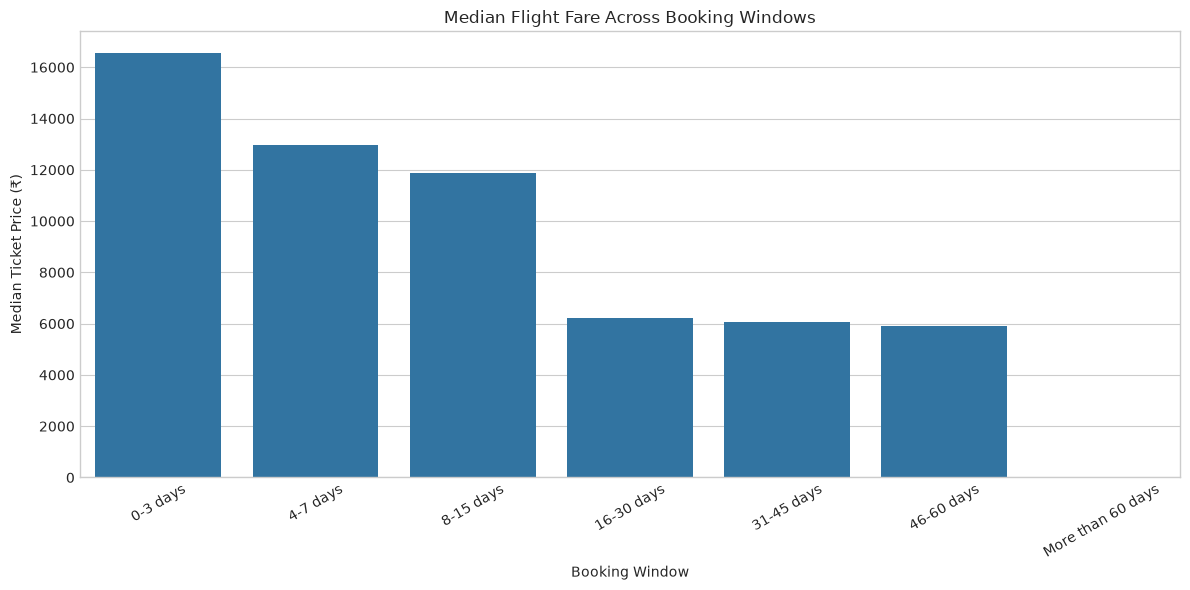

In [ ]:
# Q40. Divide booking windows into groups:
# 0-3 days, 4-7 days, 8-15 days, 16-30 days,
# 31-45 days, 46-60 days and more than 60 days, if present.
# Calculate the average and median fare in each group.

# Define booking window categories
bins = [0, 3, 7, 15, 30, 45, 60, float("inf")]

labels = [
    "0-3 days",
    "4-7 days",
    "8-15 days",
    "16-30 days",
    "31-45 days",
    "46-60 days",
    "More than 60 days"
]

# Create booking window column
df["Booking_Window"] = pd.cut(
    df["days_left"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate average and median fares
booking_summary = df.groupby(
    "Booking_Window",
    observed=False
)["price"].agg(
    Average_Fare="mean",
    Median_Fare="median",
    Observations="count"
).round(2)

display(booking_summary)

#Visualization

booking_plot = booking_summary.dropna(
    subset=["Median_Fare"]
).reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=booking_plot,
    x="Booking_Window",
    y="Median_Fare"
)

plt.title("Median Flight Fare Across Booking Windows")
plt.xlabel("Booking Window")
plt.ylabel("Median Ticket Price (₹)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [78]:
# Q41. Which booking window has the highest median ticket price?
# Which has the lowest?

valid_booking = booking_summary.dropna(
    subset=["Median_Fare"]
)

highest_window = valid_booking["Median_Fare"].idxmax()
lowest_window = valid_booking["Median_Fare"].idxmin()

print("Highest median fare booking window:", highest_window)
print("Highest median fare:", valid_booking.loc[highest_window, "Median_Fare"])

print("\nLowest median fare booking window:", lowest_window)
print("Lowest median fare:", valid_booking.loc[lowest_window, "Median_Fare"])

Highest median fare booking window: 0-3 days
Highest median fare: 16572.0

Lowest median fare booking window: 46-60 days
Lowest median fare: 5896.0


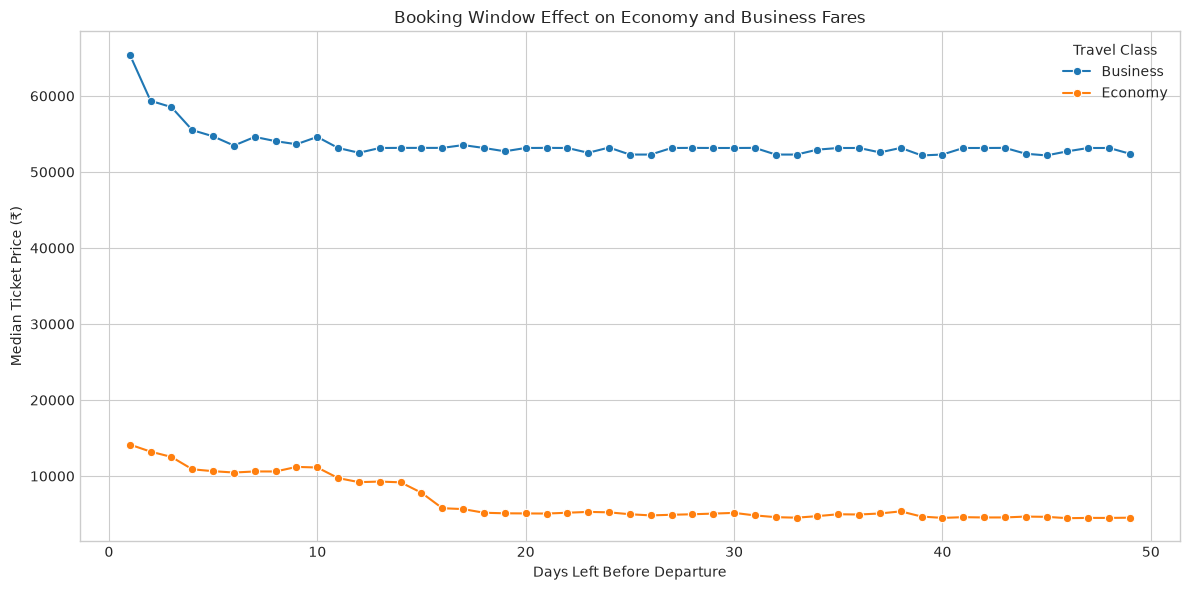

,Mean_Fare,Median_Fare
class,,
Business,52540.08,53164.0
Economy,6572.34,5772.0


In [79]:
# Q42. Does the relationship between Days Left and Price
# differ between Economy and Business class?

class_booking = df.groupby(
    ["days_left", "class"]
)["price"].median().reset_index()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=class_booking,
    x="days_left",
    y="price",
    hue="class",
    marker="o"
)

plt.title("Booking Window Effect on Economy and Business Fares")
plt.xlabel("Days Left Before Departure")
plt.ylabel("Median Ticket Price (₹)")
plt.legend(title="Travel Class")

plt.tight_layout()
plt.show()

# Calculate average and median fares by class
class_summary = df.groupby("class")["price"].agg(
    Mean_Fare="mean",
    Median_Fare="median"
)

display(class_summary.round(2))

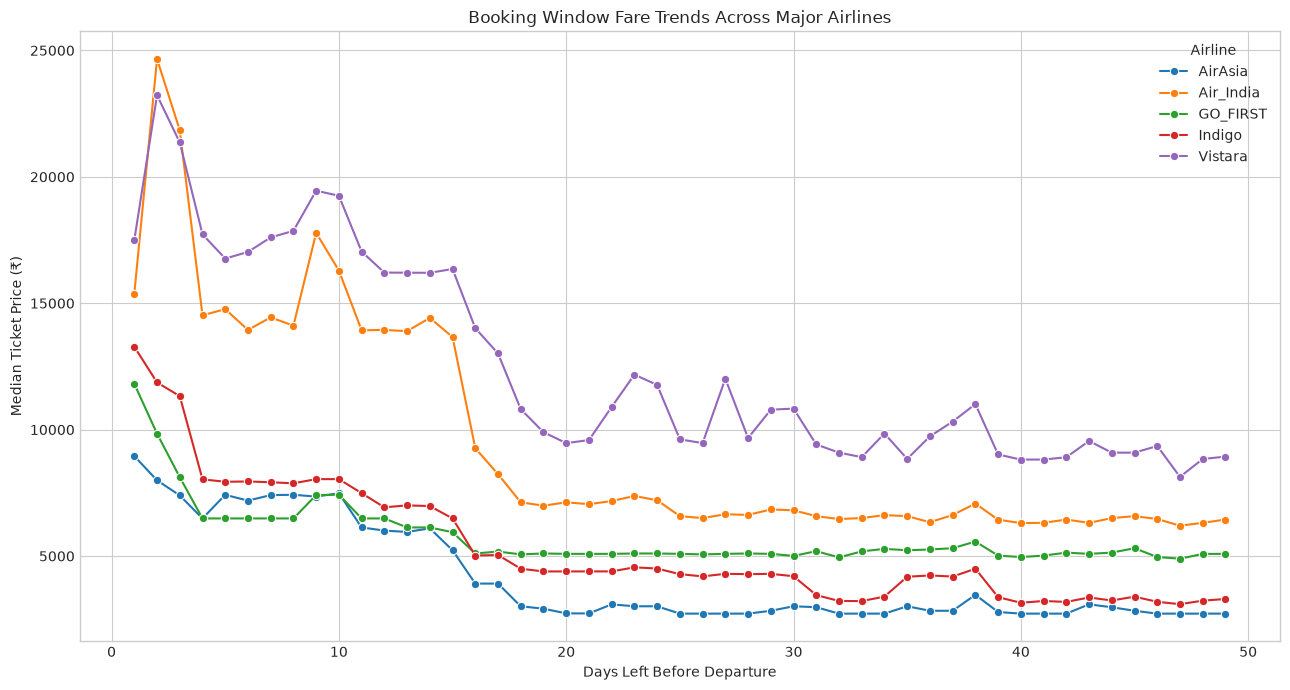

In [80]:
# Q43. Does the booking-window effect differ between airlines?
# Create a separate plot for the major airlines.

# Identify the five airlines with the highest number of records
major_airlines = df["airline"].value_counts().head(5).index

major_airline_data = df[
    df["airline"].isin(major_airlines)
]

# Calculate median fare for each airline and booking day
airline_booking = major_airline_data.groupby(
    ["days_left", "airline"]
)["price"].median().reset_index()

plt.figure(figsize=(13, 7))

sns.lineplot(
    data=airline_booking,
    x="days_left",
    y="price",
    hue="airline",
    marker="o"
)

plt.title("Booking Window Fare Trends Across Major Airlines")
plt.xlabel("Days Left Before Departure")
plt.ylabel("Median Ticket Price (₹)")
plt.legend(title="Airline")

plt.tight_layout()
plt.show()

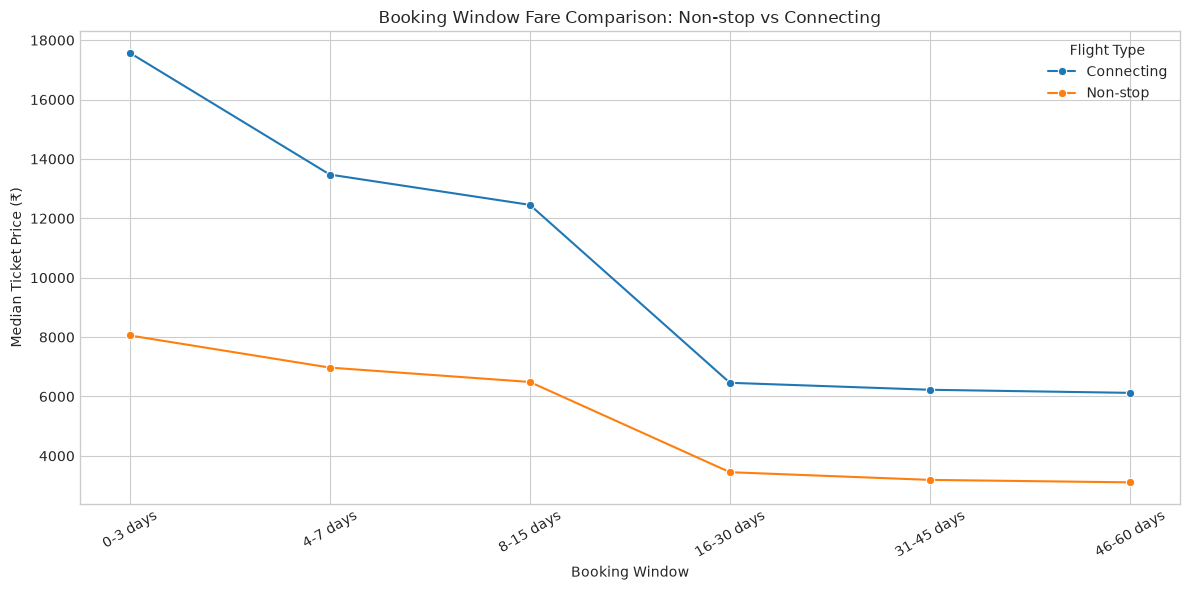

Flight_Type,Connecting,Non-stop
Booking_Window,,
0-3 days,17574.5,8055.0
4-7 days,13474.0,6973.0
8-15 days,12454.0,6489.0
16-30 days,6461.0,3450.0
31-45 days,6226.0,3191.0
46-60 days,6122.0,3108.0
More than 60 days,NaN,NaN


In [81]:
# Q44. Compare the booking-window pattern for non-stop
# and connecting flights.

# Create non-stop and connecting flight categories
df["Flight_Type"] = df["stops"].apply(
    lambda x: "Non-stop" if str(x).strip().lower() == "zero"
    else "Connecting"
)

# Calculate median fares
stop_booking = df.groupby(
    ["Booking_Window", "Flight_Type"],
    observed=False
)["price"].median().reset_index()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=stop_booking,
    x="Booking_Window",
    y="price",
    hue="Flight_Type",
    marker="o"
)

plt.title("Booking Window Fare Comparison: Non-stop vs Connecting")
plt.xlabel("Booking Window")
plt.ylabel("Median Ticket Price (₹)")
plt.xticks(rotation=30)
plt.legend(title="Flight Type")

plt.tight_layout()
plt.show()

# Display comparison table
display(
    stop_booking.pivot(
        index="Booking_Window",
        columns="Flight_Type",
        values="price"
    )
)

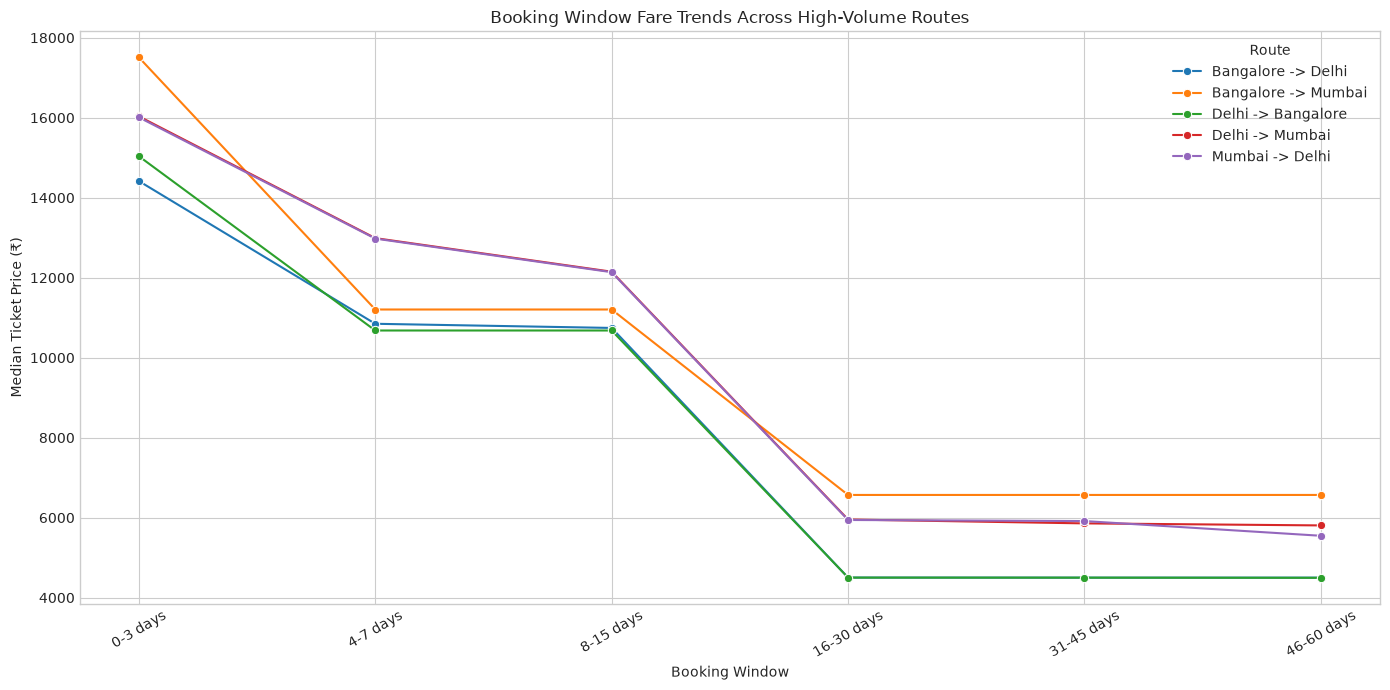

Route,Bangalore -> Delhi,Bangalore -> Mumbai,Delhi -> Bangalore,Delhi -> Mumbai,Mumbai -> Delhi
Booking_Window,,,,,
0-3 days,14417.0,17510.0,15038.0,16035.0,16010.0
4-7 days,10848.0,11205.0,10680.0,12990.0,12978.0
8-15 days,10744.0,11205.0,10680.0,12150.0,12138.0
16-30 days,4502.0,6568.0,4501.0,5954.0,5942.0
31-45 days,4500.0,6568.0,4500.0,5857.0,5915.0
46-60 days,4500.0,6568.0,4496.0,5806.0,5547.0
More than 60 days,NaN,NaN,NaN,NaN,NaN


In [82]:
# Q45. Select a few high-volume routes and investigate their
# booking-window trends independently.
# Are the trends consistent across routes?

# Create route column
df["Route"] = (
    df["source_city"] + " -> " + df["destination_city"]
)

# Select five routes with the highest number of observations
top_routes = df["Route"].value_counts().head(5).index

route_data = df[df["Route"].isin(top_routes)]

# Calculate median fare for each route and booking window
route_booking = route_data.groupby(
    ["Booking_Window", "Route"],
    observed=False
)["price"].median().reset_index()

# Plot route-wise trends
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=route_booking,
    x="Booking_Window",
    y="price",
    hue="Route",
    marker="o"
)

plt.title("Booking Window Fare Trends Across High-Volume Routes")
plt.xlabel("Booking Window")
plt.ylabel("Median Ticket Price (₹)")
plt.xticks(rotation=30)
plt.legend(title="Route")

plt.tight_layout()
plt.show()

# Display route-wise median fares
display(
    route_booking.pivot(
        index="Booking_Window",
        columns="Route",
        values="price"
    )
)

In [83]:
# Q46. Calculate the percentage change in median price
# between the earliest and latest booking-window groups.
# State clearly which groups are being compared.

# Calculate median fare for each booking window
window_medians = df.groupby(
    "Booking_Window",
    observed=False
)["price"].median().dropna()

# Identify available booking windows
available_windows = window_medians.index.tolist()

# Latest booking = closest to departure
latest_booking = available_windows[0]

# Earliest booking = furthest from departure
earliest_booking = available_windows[-1]

# Extract median fares
latest_median = window_medians.loc[latest_booking]
earliest_median = window_medians.loc[earliest_booking]

# Calculate percentage change
percentage_change = (
    (latest_median - earliest_median) /
    earliest_median
) * 100

print("Earliest booking window:", earliest_booking)
print("Earliest booking median fare: ₹", round(earliest_median, 2))

print("\nLatest booking window:", latest_booking)
print("Latest booking median fare: ₹", round(latest_median, 2))

print("\nPercentage change in median fare:",
      round(percentage_change, 2), "%")

Earliest booking window: 46-60 days
Earliest booking median fare: ₹ 5896.0

Latest booking window: 0-3 days
Latest booking median fare: ₹ 16572.0

Percentage change in median fare: 181.07 %


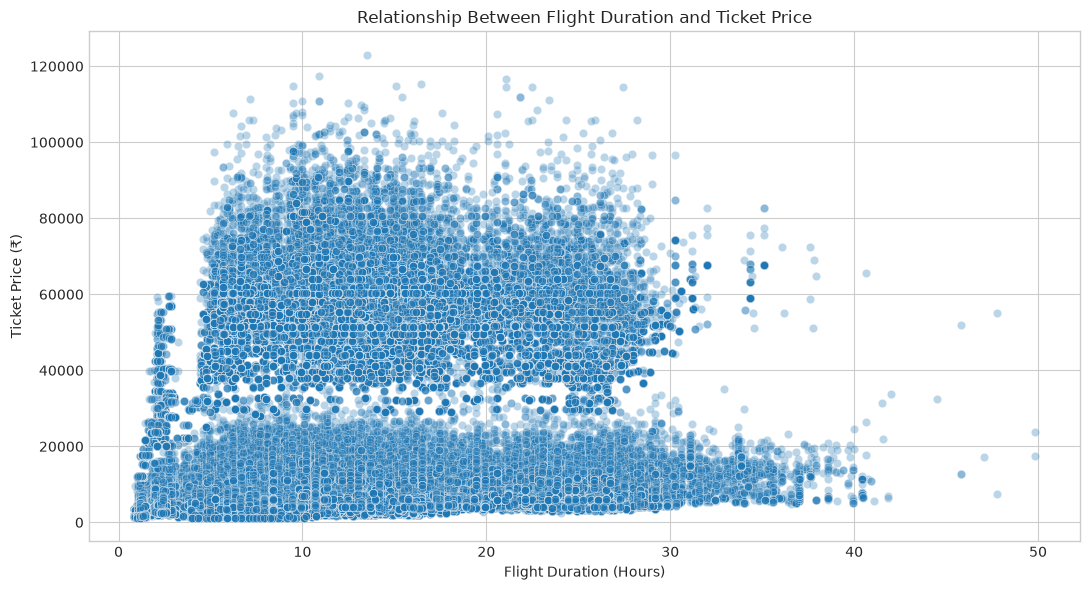

Pearson Correlation: 0.204
Spearman Correlation: 0.319


In [84]:
# Q47. Does flight duration have a relationship with ticket price?
# Create a scatter plot and calculate Pearson and Spearman correlations.

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df,
    x="duration",
    y="price",
    alpha=0.3
)

plt.title("Relationship Between Flight Duration and Ticket Price")
plt.xlabel("Flight Duration (Hours)")
plt.ylabel("Ticket Price (₹)")

plt.tight_layout()
plt.show()

# Calculate Pearson and Spearman correlations
pearson_corr = df["duration"].corr(
    df["price"], method="pearson"
)

spearman_corr = df["duration"].corr(
    df["price"], method="spearman"
)

print("Pearson Correlation:", round(pearson_corr, 3))
print("Spearman Correlation:", round(spearman_corr, 3))

,Mean_Fare,Median_Fare,Minimum_Fare,Maximum_Fare,Observations
stops,,,,,
zero,9375.94,4499.0,1105,59573,36004
one,22900.99,7959.0,1105,123071,250863
two_or_more,14113.45,8307.0,1966,117307,13286


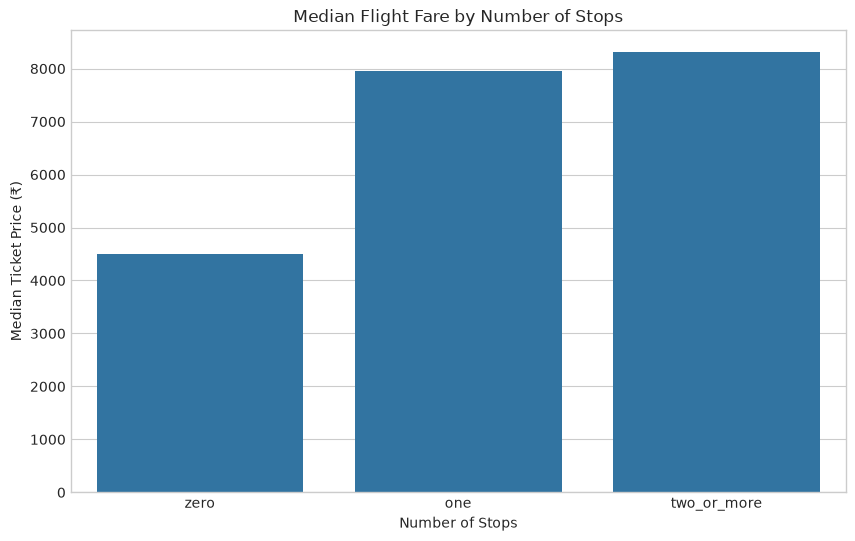

In [85]:
# Q48. Compare median prices for non-stop, one-stop,
# two-stop and other available stop categories.

stop_price_summary = df.groupby(
    "stops"
)["price"].agg(
    Mean_Fare="mean",
    Median_Fare="median",
    Minimum_Fare="min",
    Maximum_Fare="max",
    Observations="count"
).sort_values("Median_Fare")

display(stop_price_summary.round(2))

# Visualize median fare by stop category
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="stops",
    y="price",
    estimator="median",
    errorbar=None
)

plt.title("Median Flight Fare by Number of Stops")
plt.xlabel("Number of Stops")
plt.ylabel("Median Ticket Price (₹)")

plt.show()

,Median_Duration,Median_Fare,Average_Duration,Average_Fare,Observations
Route,,,,,
Bangalore -> Chennai,13.25,9241.0,14.48,23321.85,6410
Bangalore -> Delhi,8.67,7164.0,9.78,17723.31,13756
Bangalore -> Hyderabad,13.42,7813.0,14.16,21226.12,8928
Bangalore -> Kolkata,11.92,8112.0,13.10,23500.06,10028
Bangalore -> Mumbai,10.67,7113.0,10.91,23128.62,12939
Chennai -> Bangalore,12.58,10469.0,13.95,25081.85,6493
Chennai -> Delhi,10.00,7352.0,11.15,18981.86,9783
Chennai -> Hyderabad,12.17,7373.0,13.15,21591.35,6103
Chennai -> Kolkata,12.50,8394.0,14.52,22669.93,6983


Correlation between route median duration and fare: 0.59


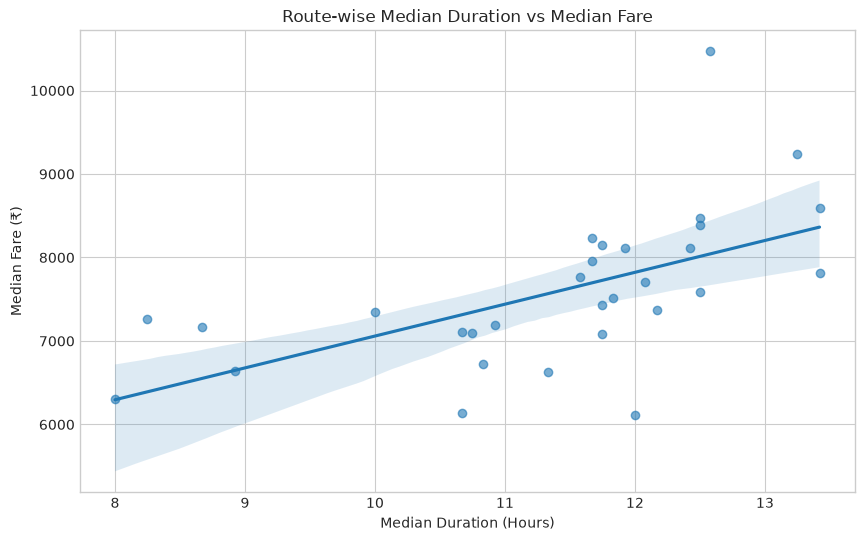

In [86]:
# Q49. Are longer flights more expensive within the same
# source-destination route? Compare duration and price
# after controlling for route.

# Create route feature
df["Route"] = (
    df["source_city"] + " -> " + df["destination_city"]
)

# Calculate route-wise duration and fare statistics
route_duration = df.groupby("Route").agg(
    Median_Duration=("duration", "median"),
    Median_Fare=("price", "median"),
    Average_Duration=("duration", "mean"),
    Average_Fare=("price", "mean"),
    Observations=("price", "count")
)

# Retain routes with at least 30 observations
route_duration = route_duration[
    route_duration["Observations"] >= 30
]

display(route_duration.round(2))

# Correlation across route-level median values
route_correlation = route_duration[
    ["Median_Duration", "Median_Fare"]
].corr().iloc[0, 1]

print(
    "Correlation between route median duration and fare:",
    round(route_correlation, 3)
)

# Scatter plot
plt.figure(figsize=(10, 6))

sns.regplot(
    data=route_duration,
    x="Median_Duration",
    y="Median_Fare",
    scatter_kws={"alpha": 0.6}
)

plt.title("Route-wise Median Duration vs Median Fare")
plt.xlabel("Median Duration (Hours)")
plt.ylabel("Median Fare (₹)")

plt.show()

,Mean_Fare,Median_Fare,Observations
Departure_Period,,,
Afternoon,18179.20,6663.0,47794
Early Morning,20370.68,7212.0,66790
Evening,21232.36,7425.0,65102
Morning,21630.76,8112.0,71146
Night,22697.61,7572.0,49321


Period with highest median fare: Morning
Highest median fare: 8112.0


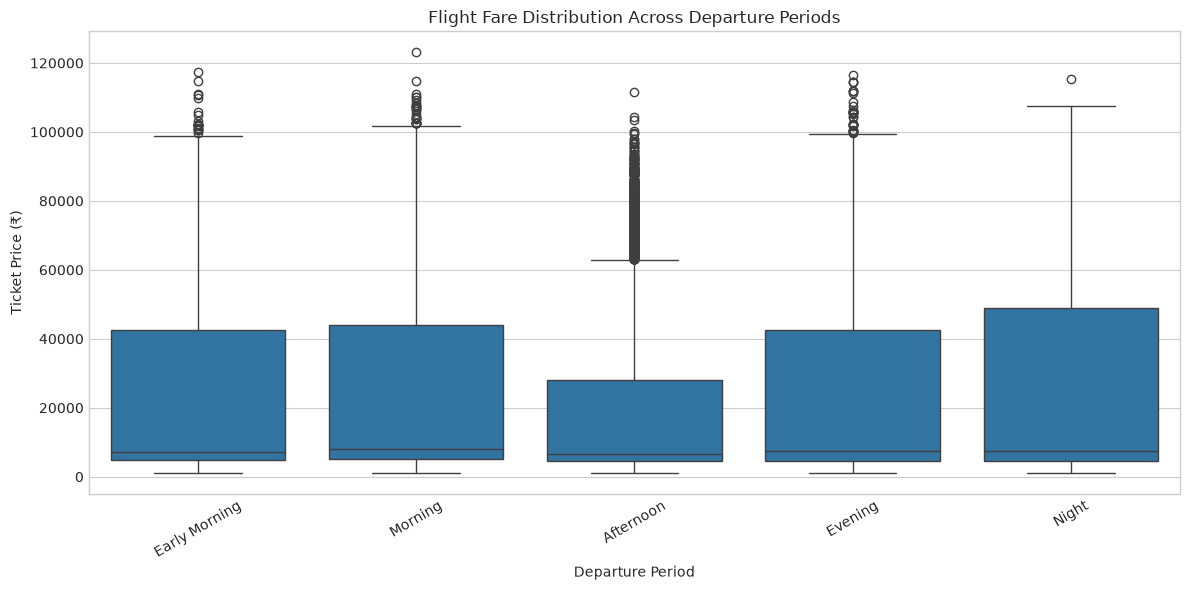

In [94]:
# Q50. Compare fare distributions across departure periods:
# early morning, morning, afternoon, evening and night.
# Which time category has the highest median fare?

# Clean departure time categories
df["Departure_Period"] = (
    df["departure_time"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace("_", " ", regex=False)
)

# Standardize departure categories
period_mapping = {
    "early morning": "Early Morning",
    "morning": "Morning",
    "afternoon": "Afternoon",
    "evening": "Evening",
    "night": "Night",
    "late night": "Night"
}

df["Departure_Period"] = df["Departure_Period"].map(period_mapping)

# Calculate fare statistics
departure_summary = df.groupby(
    "Departure_Period"
)["price"].agg(
    Mean_Fare="mean",
    Median_Fare="median",
    Observations="count"
).round(2)

display(departure_summary)

# Identify highest median fare
highest_period = departure_summary["Median_Fare"].idxmax()

print("Period with highest median fare:", highest_period)
print("Highest median fare:",
      departure_summary.loc[highest_period, "Median_Fare"])

# Plot fare distributions
period_order = [
    "Early Morning",
    "Morning",
    "Afternoon",
    "Evening",
    "Night"
]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Departure_Period",
    y="price",
    order=period_order
)

plt.title("Flight Fare Distribution Across Departure Periods")
plt.xlabel("Departure Period")
plt.ylabel("Ticket Price (₹)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


0             Night
1           Morning
2     Early_Morning
3         Afternoon
4           Morning
5         Afternoon
6           Morning
7           Evening
8           Morning
9           Evening
10          Evening
11        Afternoon
12          Morning
13        Afternoon
14          Evening
Name: arrival_time, dtype: str
str
Missing values: 0


,Mean_Fare,Median_Fare,Observations
Arrival_Period,,,
Afternoon,18494.60,6714.0,38139
Early Morning,14993.14,5800.0,15417
Evening,23044.37,8854.0,78323
Late Night,11284.91,4867.0,14001
Morning,22231.08,7687.0,62735
Night,21586.76,7584.0,91538


Arrival period with highest median fare: Evening
Highest median fare: 8854.0


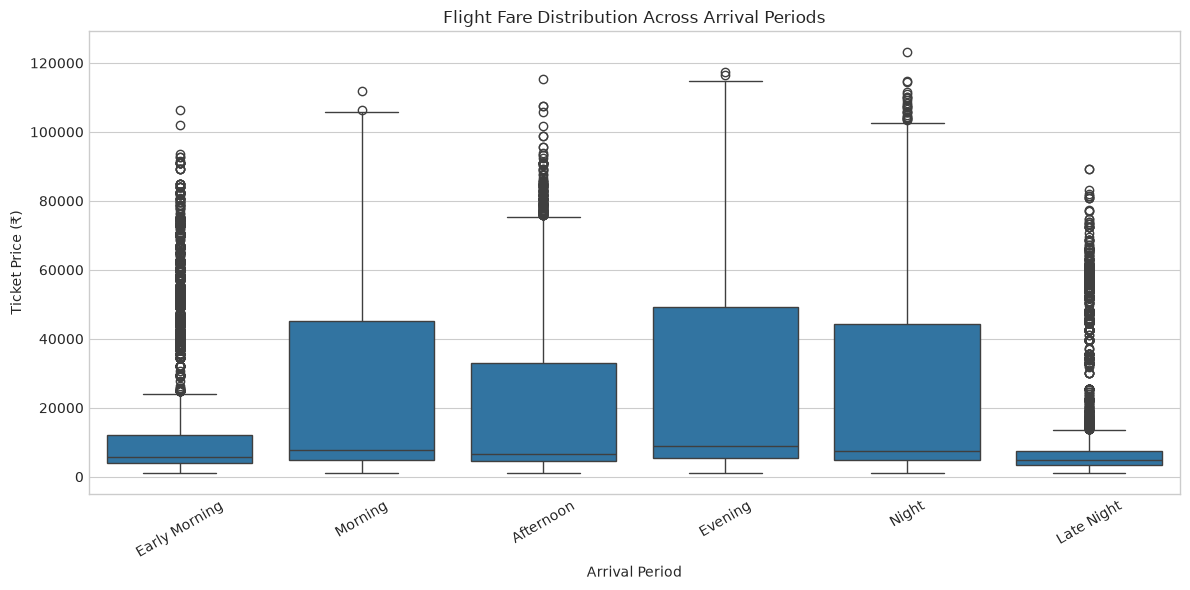

In [103]:
# Q51. Repeat the analysis for arrival time.
# Does arrival period show a similar pattern to departure period?

print(df["arrival_time"].head(15))
print(df["arrival_time"].dtype)
print("Missing values:", df["arrival_time"].isna().sum())

# Step 1: Standardize arrival categories
df["Arrival_Period"] = (
    df["arrival_time"]
    .astype(str)
    .str.strip()
    .str.replace("_", " ", regex=False)
)

# Step 2: Calculate fare statistics
arrival_summary = df.groupby(
    "Arrival_Period"
)["price"].agg(
    Mean_Fare="mean",
    Median_Fare="median",
    Observations="count"
).round(2)

display(arrival_summary)

# Step 3: Identify highest median fare
print(
    "Arrival period with highest median fare:",
    arrival_summary["Median_Fare"].idxmax()
)

print(
    "Highest median fare:",
    arrival_summary["Median_Fare"].max()
)

# Step 4: Plot arrival fare distribution
arrival_order = [
    "Early Morning",
    "Morning",
    "Afternoon",
    "Evening",
    "Night",
    "Late Night"
]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Arrival_Period",
    y="price",
    order=arrival_order
)

plt.title("Flight Fare Distribution Across Arrival Periods")
plt.xlabel("Arrival Period")
plt.ylabel("Ticket Price (₹)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

,Mean_Duration,Median_Duration,Minimum_Duration,Maximum_Duration,Observations
stops,,,,,
one,13.50,12.25,2.92,49.83,250863
two_or_more,15.32,12.67,3.92,49.83,13286
zero,2.19,2.25,0.83,3.58,36004


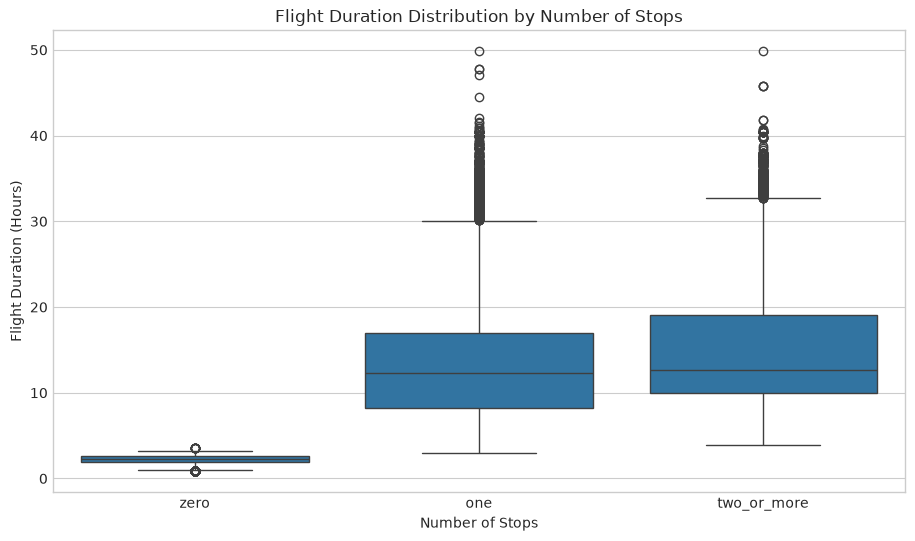

In [91]:
# Q52. Does a longer duration necessarily mean more stops?
# Compare duration distributions across stop categories.

# Calculate duration statistics by stops
duration_stops = df.groupby("stops")["duration"].agg(
    Mean_Duration="mean",
    Median_Duration="median",
    Minimum_Duration="min",
    Maximum_Duration="max",
    Observations="count"
)

display(duration_stops.round(2))

# Visualize duration distributions
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="stops",
    y="duration"
)

plt.title("Flight Duration Distribution by Number of Stops")
plt.xlabel("Number of Stops")
plt.ylabel("Flight Duration (Hours)")

plt.show()

In [92]:
# Q53. Which airlines offer the shortest median duration
# for each route? Are they also the most expensive?

# Calculate median duration and fare for each route and airline
airline_route_duration = df.groupby(
    ["Route", "airline"]
).agg(
    Median_Duration=("duration", "median"),
    Median_Fare=("price", "median"),
    Observations=("price", "count")
).reset_index()

# Retain combinations with sufficient observations
airline_route_duration = airline_route_duration[
    airline_route_duration["Observations"] >= 10
]

# Identify airline with shortest median duration per route
shortest_duration = airline_route_duration.loc[
    airline_route_duration.groupby("Route")[
        "Median_Duration"
    ].idxmin()
].copy()

# Identify airline with highest median fare per route
most_expensive = airline_route_duration.loc[
    airline_route_duration.groupby("Route")[
        "Median_Fare"
    ].idxmax()
].copy()

# Combine the results
comparison = shortest_duration[
    ["Route", "airline", "Median_Duration", "Median_Fare"]
].rename(columns={
    "airline": "Fastest Airline",
    "Median_Duration": "Shortest Median Duration",
    "Median_Fare": "Fastest Airline Median Fare"
})

comparison = comparison.merge(
    most_expensive[
        ["Route", "airline", "Median_Fare"]
    ].rename(columns={
        "airline": "Most Expensive Airline",
        "Median_Fare": "Highest Median Fare"
    }),
    on="Route"
)

display(comparison.round(2))

,Route,Fastest Airline,Shortest Median Duration,Fastest Airline Median Fare,Most Expensive Airline,Highest Median Fare
0,Bangalore -> Chennai,AirAsia,1.00,1715.0,Air_India,13316.5
1,Bangalore -> Delhi,Indigo,5.92,4500.0,Vistara,32923.0
2,Bangalore -> Hyderabad,SpiceJet,1.08,4338.0,Vistara,14150.0
3,Bangalore -> Kolkata,SpiceJet,5.75,4814.0,Vistara,51817.0
4,Bangalore -> Mumbai,Indigo,5.17,4435.0,Vistara,20760.0
5,Chennai -> Bangalore,Indigo,1.08,1654.0,Vistara,15439.0
6,Chennai -> Delhi,Indigo,6.33,4071.0,Vistara,16140.0
7,Chennai -> Hyderabad,GO_FIRST,1.25,1105.0,Vistara,15563.0
8,Chennai -> Kolkata,SpiceJet,2.50,4620.0,Air_India,15963.0
9,Chennai -> Mumbai,GO_FIRST,1.92,3000.0,Vistara,16875.0


,Pearson_Correlation,Spearman_Correlation
class,,
Business,0.243,0.165
Economy,0.288,0.358


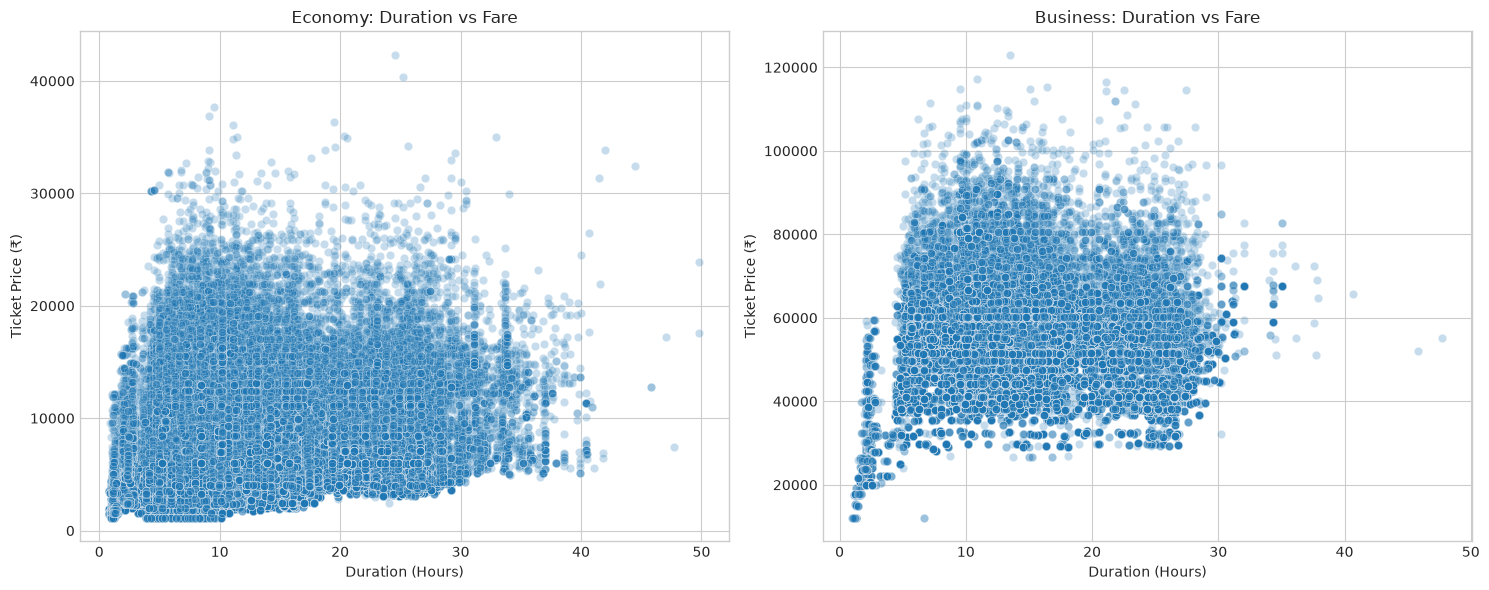

In [93]:
# Q54. Compare the relationship between duration and fare
# for Economy and Business class separately.

# Calculate correlations separately
class_correlations = df.groupby("class").apply(
    lambda group: pd.Series({
        "Pearson_Correlation": group["duration"].corr(
            group["price"], method="pearson"
        ),
        "Spearman_Correlation": group["duration"].corr(
            group["price"], method="spearman"
        )
    }),
    include_groups=False
)

display(class_correlations.round(3))

# Create separate scatter plots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, travel_class in zip(
    axes,
    df["class"].dropna().unique()
):
    class_data = df[df["class"] == travel_class]

    sns.scatterplot(
        data=class_data,
        x="duration",
        y="price",
        alpha=0.25,
        ax=ax
    )

    ax.set_title(f"{travel_class}: Duration vs Fare")
    ax.set_xlabel("Duration (Hours)")
    ax.set_ylabel("Ticket Price (₹)")

plt.tight_layout()
plt.show()